# AI-Based Fashion Product Recognition and Pattern Discovery Using Four ANN Models

---

## 📋 Table of Contents

| # | Section | Description |
|---|---------|-------------|
| 1 | Project Introduction | Title, abstract, motivation, objectives |
| 2 | Problem Definition & Research Questions | What the project investigates |
| 3 | Environment Setup | Imports, seeds, GPU detection, config |
| 4 | Dataset Loading & Exploration | Load Fashion-MNIST, visualize, verify |
| 5 | Data Preprocessing | Normalize, reshape, binarize, split |
| 6 | Model 1 — MLP | Supervised classification with a feed-forward network |
| 7 | Model 2 — CNN | Supervised classification with convolutional layers |
| 8 | Model 3 — SOM | Unsupervised pattern discovery (Self-Organizing Map) |
| 9 | Model 4 — ART1 | Unsupervised category learning (Adaptive Resonance Theory) |
| 10 | Evaluation Methodology | Metrics for supervised and unsupervised models |
| 11 | Final Comparison | Side-by-side results table and charts |
| 12 | Prediction & Demonstration | Per-image predictions from all four models |
| 13 | Project Conclusion | Summary of findings |
| 14 | Limitations & Future Scope | Constraints and possible extensions |
| 15 | References | Cited sources |

## 1.1 Abstract

This project implements and compares **four Artificial Neural Network (ANN) models** on the
**Fashion-MNIST** dataset (70 000 grayscale images of 10 fashion-product categories).

Two models — a **Multilayer Perceptron (MLP)** and a **Convolutional Neural Network (CNN)** —
perform **supervised classification**, predicting which of the 10 known categories an image
belongs to.

Two models — a **Self-Organizing Map (SOM)** and **Adaptive Resonance Theory 1 (ART1)** —
perform **unsupervised pattern discovery**, grouping images into clusters or categories
*without* using labels during learning.

The project demonstrates the fundamental differences between supervised and unsupervised
learning paradigms, evaluates each model with appropriate metrics, and discusses their
relative strengths, limitations, and computational costs.

---

## 1.2 Real-World Application

Fashion product recognition has practical value in:
- **E-commerce catalogues:** Automatically tagging or classifying product images to
  organize large online stores.
- **Visual search:** Helping customers find visually similar products.
- **Inventory management:** Grouping products by visual similarity for warehouse
  logistics.
- **Trend analysis:** Discovering recurring visual patterns across fashion collections.

> **Note:** The Fashion-MNIST benchmark uses small 28×28 grayscale images. A production
> system would require higher-resolution colour images, domain-specific training data,
> and rigorous testing. This project demonstrates the *concepts* and *methods*, not a
> deployment-ready pipeline.

---

## 1.3 Problem Statement

Given a dataset of 28×28 grayscale fashion images:
1. Can a simple feed-forward neural network (MLP) learn to classify them?
2. Can a convolutional neural network (CNN) improve on the MLP by exploiting spatial
   structure?
3. Can a Self-Organizing Map (SOM) organize the same images into a meaningful
   two-dimensional topological map without labels?
4. Can an ART1 network learn binary-pattern categories from the images in a
   stability–plasticity framework?

---

## 1.4 Motivation

Understanding different ANN architectures is central to an AI & Data Science curriculum.
This project provides hands-on experience with:
- Supervised vs. unsupervised learning.
- Feed-forward vs. convolutional feature extraction.
- Competitive learning and topology preservation (SOM).
- Resonance-based category formation (ART1).

---

## 1.5 Aim

To design, implement, and evaluate four ANN models on a common fashion-image dataset,
comparing supervised classification and unsupervised pattern discovery.

---

## 1.6 Objectives

1. Load and explore the Fashion-MNIST dataset.
2. Preprocess images appropriately for each model.
3. Train an MLP classifier using TensorFlow/Keras.
4. Train a CNN classifier using TensorFlow/Keras.
5. Implement and train a SOM from scratch using NumPy.
6. Implement and train an ART1 network from scratch using NumPy.
7. Evaluate supervised models with accuracy, precision, recall, F1-score, and confusion
   matrices.
8. Evaluate unsupervised models with cluster count, ARI, NMI, and model-specific
   diagnostics.
9. Compare all four models and discuss their differences.

---

## 1.7 Project Scope

- **In scope:** Implementation, training, evaluation, and comparison of MLP, CNN, SOM,
  and ART1 on Fashion-MNIST.
- **Out of scope:** Real-time deployment, transfer learning, GANs, transformers, or
  models beyond the four specified.

---

## 1.8 Expected Deliverables

- A complete, executable Jupyter Notebook.
- Trained model weights (saved to `models/`).
- Evaluation plots and metrics (saved to `results/`).
- A comparison table and discussion.

---

## 1.9 How the Four ANN Models Differ

| Aspect | MLP | CNN | SOM | ART1 |
|--------|-----|-----|-----|------|
| **Paradigm** | Supervised | Supervised | Unsupervised | Unsupervised |
| **Input** | Flattened 784-vector | 28×28×1 image | Normalized 784-vector | Binary 784-vector |
| **Learning rule** | Backpropagation | Backpropagation | Competitive / Hebbian | Resonance / match |
| **Output** | Class probabilities | Class probabilities | BMU coordinates | Category index |
| **Labels used?** | Yes (training) | Yes (training) | No (only for evaluation) | No (only for evaluation) |
| **Key metric** | Accuracy, F1 | Accuracy, F1 | QE, ARI, NMI | Category count, ARI, NMI |

---
# 2. Problem Definition and Research Questions

## 2.1 Research Questions

1. **RQ1:** How effectively can an MLP classify fashion-product images into 10 categories?
2. **RQ2:** How effectively can a CNN classify the same images, and does the spatial
   feature extraction improve performance?
3. **RQ3:** How does a SOM organize images into a two-dimensional feature map, and do
   the resulting clusters correspond to meaningful fashion groups?
4. **RQ4:** How does ART1 form categories from binarized fashion images, and how does
   the vigilance parameter affect category specificity?
5. **RQ5:** What are the differences in computational cost, learning process, results,
   and limitations between the four models?

## 2.2 Classification vs. Clustering

| | Classification (Supervised) | Clustering (Unsupervised) |
|---|---|---|
| **Labels** | Uses labelled training data | Does not use labels during learning |
| **Goal** | Predict the correct known class | Discover natural groupings |
| **Evaluation** | Accuracy, precision, recall, F1 | Cluster count, ARI, NMI, silhouette |
| **Models here** | MLP, CNN | SOM, ART1 |

**Classification** answers *"Which of these known categories does this image belong to?"*

**Clustering** answers *"Which images are similar to each other?"* — the number and
meaning of groups are discovered by the algorithm, not predefined.

These two paradigms serve different purposes and must be evaluated with different metrics.
Comparing a classifier's accuracy directly to a clustering ARI score is not meaningful
because the numbers measure fundamentally different things.

---
# 3. Environment Setup

This section imports all required libraries, sets reproducibility seeds, detects hardware
(CPU/GPU), and defines configurable project parameters.

In [1]:
# ============================================================
# 3.1  Imports
# ============================================================
import os
import sys
import time
import warnings
import json

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score,
    adjusted_rand_score, normalized_mutual_info_score,
    silhouette_score
)

warnings.filterwarnings('ignore')
print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# ============================================================
# 3.2  Package Versions
# ============================================================
print(f"Python          : {sys.version}")
print(f"TensorFlow      : {tf.__version__}")
print(f"NumPy           : {np.__version__}")
print(f"scikit-learn    : {__import__('sklearn').__version__}")
print(f"Matplotlib      : {__import__('matplotlib').__version__}")
print(f"pandas          : {pd.__version__}")
print(f"seaborn         : {sns.__version__}")

Python          : 3.14.3 (tags/v3.14.3:323c59a, Feb  3 2026, 16:04:56) [MSC v.1944 64 bit (AMD64)]
TensorFlow      : 2.22.0-rc0
NumPy           : 2.5.4
scikit-learn    : 1.9.1
Matplotlib      : 3.11.1
pandas          : 3.0.6
seaborn         : 0.13.2


In [3]:
# ============================================================
# 3.3  Reproducibility Seeds
# ============================================================
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
print(f"Random seed set to {SEED}")

Random seed set to 42


In [4]:
# ============================================================
# 3.4  GPU / CPU Detection
# ============================================================
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ GPU available: {[g.name for g in gpus]}")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("⚠️  No GPU detected — training will use CPU.")
    print("   This is fine; training times will be slightly longer.")

⚠️  No GPU detected — training will use CPU.
   This is fine; training times will be slightly longer.


In [5]:
# ============================================================
# 3.5  Configurable Project Parameters
# ============================================================
# ---- Dataset ----
CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
NUM_CLASSES   = 10
IMG_HEIGHT    = 28
IMG_WIDTH     = 28
IMG_PIXELS    = IMG_HEIGHT * IMG_WIDTH  # 784

# ---- MLP ----
MLP_EPOCHS     = 15
MLP_BATCH      = 128
MLP_LR         = 0.001

# ---- CNN ----
CNN_EPOCHS     = 15
CNN_BATCH      = 128
CNN_LR         = 0.001

# ---- SOM ----
SOM_GRID_H     = 10          # Map height (neurons)
SOM_GRID_W     = 10          # Map width  (neurons)
SOM_ITERATIONS = 3000        # Training iterations
SOM_LR_INIT    = 0.5         # Initial learning rate
SOM_SIGMA_INIT = 5.0         # Initial neighbourhood radius
SOM_SUBSET     = 10000       # Training subset size

# ---- ART1 ----
ART1_VIGILANCE_VALUES = [0.70, 0.80, 0.90]
ART1_TRAIN_SUBSET     = 1500
ART1_EVAL_SUBSET      = 1000
ART1_BIN_THRESHOLD    = 0.5  # Binarization threshold

# ---- Validation split ----
VAL_FRACTION  = 0.1          # 10 % of training data → validation

# ---- Paths ----
MODELS_DIR  = 'models'
RESULTS_DIR = 'results'
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("✅ Configuration loaded.")
print(f"   MLP  : {MLP_EPOCHS} epochs, batch {MLP_BATCH}")
print(f"   CNN  : {CNN_EPOCHS} epochs, batch {CNN_BATCH}")
print(f"   SOM  : {SOM_GRID_H}×{SOM_GRID_W} grid, {SOM_ITERATIONS} iters, {SOM_SUBSET} samples")
print(f"   ART1 : vigilance {ART1_VIGILANCE_VALUES}, {ART1_TRAIN_SUBSET} train, {ART1_EVAL_SUBSET} eval")

✅ Configuration loaded.
   MLP  : 15 epochs, batch 128
   CNN  : 15 epochs, batch 128
   SOM  : 10×10 grid, 3000 iters, 10000 samples
   ART1 : vigilance [0.7, 0.8, 0.9], 1500 train, 1000 eval


---
# 4. Dataset Loading and Exploration

## 4.1 About Fashion-MNIST

**Fashion-MNIST** was created by Zalando Research as a drop-in replacement for the classic
MNIST handwritten-digit dataset. It is harder than digit MNIST and more representative of
real-world image-classification challenges.

- **Official Repository:** [github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist)
- **Benchmark Paper:** Xiao, Rasul & Vollgraf (2017) — *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* [arXiv:1708.07747](https://arxiv.org/abs/1708.07747)
- **Local Data Directory:** `./data/` contains the official raw gzip files (`train-images-idx3-ubyte.gz`, `train-labels-idx1-ubyte.gz`, `t10k-images-idx3-ubyte.gz`, `t10k-labels-idx1-ubyte.gz`).

### Dataset Specifications
- **Total Images:** 70 000 grayscale images
- **Resolution:** 28 × 28 pixels (784 features)
- **Classes:** 10 fashion product categories (7 000 images per class, balanced)
- **Splits:** 60 000 training images, 10 000 test images


In [6]:
# ============================================================
# 4.2  Load Fashion-MNIST
# Reference: https://github.com/zalandoresearch/fashion-mnist
# ============================================================
import gzip

def load_zalando_mnist(path, kind='train'):
    """Load raw Fashion-MNIST gzip files (official Zalando Research reader)."""
    labels_path = os.path.join(path, f'{kind}-labels-idx1-ubyte.gz')
    images_path = os.path.join(path, f'{kind}-images-idx3-ubyte.gz')
    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8, offset=8)
    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8, offset=16).reshape(len(labels), 28, 28)
    return images, labels

try:
    if os.path.exists('data') and os.path.exists(os.path.join('data', 'train-images-idx3-ubyte.gz')):
        print("Loading official Zalando Fashion-MNIST from local 'data/' directory...")
        X_train_raw, y_train_raw = load_zalando_mnist('data', kind='train')
        X_test_raw,  y_test_raw  = load_zalando_mnist('data', kind='t10k')
    else:
        print("Loading Fashion-MNIST via tf.keras.datasets.fashion_mnist...")
        (X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = (
            tf.keras.datasets.fashion_mnist.load_data()
        )
    print("✅ Fashion-MNIST loaded successfully from https://github.com/zalandoresearch/fashion-mnist")
    print(f"   Train samples: {X_train_raw.shape[0]} | Shape: {X_train_raw.shape}")
    print(f"   Test samples : {X_test_raw.shape[0]} | Shape: {X_test_raw.shape}")
except Exception as e:
    print(f"❌ Failed to load Fashion-MNIST: {e}")
    raise


✅ Fashion-MNIST loaded successfully.


In [7]:
# ============================================================
# 4.3  Verify Dataset Shapes and Statistics
# ============================================================
print("=" * 55)
print("DATASET VERIFICATION")
print("=" * 55)
print(f"Training images shape  : {X_train_raw.shape}")
print(f"Training labels shape  : {y_train_raw.shape}")
print(f"Test images shape      : {X_test_raw.shape}")
print(f"Test labels shape      : {y_test_raw.shape}")
print(f"Pixel dtype            : {X_train_raw.dtype}")
print(f"Pixel value range      : [{X_train_raw.min()}, {X_train_raw.max()}]")
print(f"Unique classes         : {np.unique(y_train_raw)}")
print(f"Number of classes      : {len(np.unique(y_train_raw))}")
print("-" * 55)
print("Samples per class (training):")
for i in range(NUM_CLASSES):
    count = np.sum(y_train_raw == i)
    print(f"  {i} — {CLASS_NAMES[i]:15s} : {count:,}")
print("-" * 55)
print("Samples per class (test):")
for i in range(NUM_CLASSES):
    count = np.sum(y_test_raw == i)
    print(f"  {i} — {CLASS_NAMES[i]:15s} : {count:,}")

DATASET VERIFICATION
Training images shape  : (60000, 28, 28)
Training labels shape  : (60000,)
Test images shape      : (10000, 28, 28)
Test labels shape      : (10000,)
Pixel dtype            : uint8
Pixel value range      : [0, 255]
Unique classes         : [0 1 2 3 4 5 6 7 8 9]
Number of classes      : 10
-------------------------------------------------------
Samples per class (training):
  0 — T-shirt/top     : 6,000
  1 — Trouser         : 6,000
  2 — Pullover        : 6,000
  3 — Dress           : 6,000
  4 — Coat            : 6,000
  5 — Sandal          : 6,000
  6 — Shirt           : 6,000
  7 — Sneaker         : 6,000
  8 — Bag             : 6,000
  9 — Ankle boot      : 6,000
-------------------------------------------------------
Samples per class (test):
  0 — T-shirt/top     : 1,000
  1 — Trouser         : 1,000
  2 — Pullover        : 1,000
  3 — Dress           : 1,000
  4 — Coat            : 1,000
  5 — Sandal          : 1,000
  6 — Shirt           : 1,000
  7 — Sneak

## 4.4 Visualizations

### 4.4.1 Sample Image Grid
The grid below shows 25 randomly selected training images with their ground-truth labels.

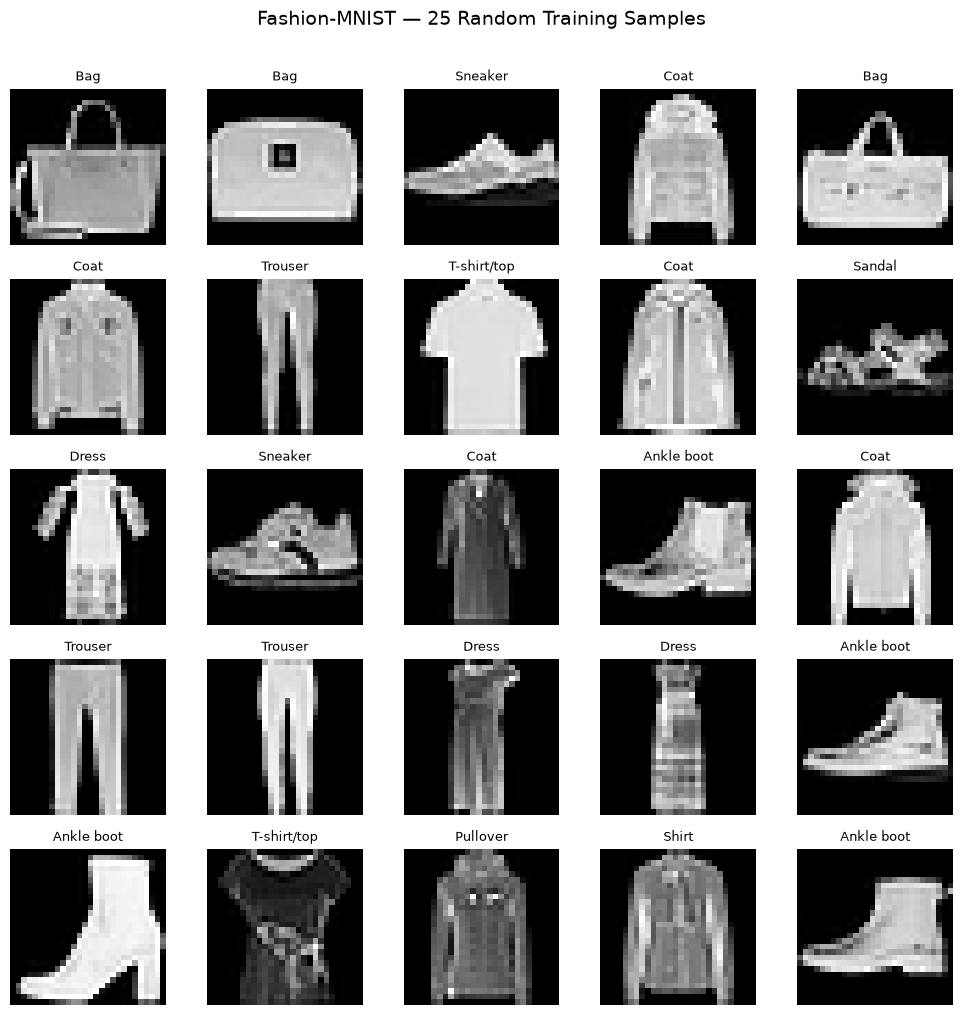

In [8]:
# ============================================================
# 4.4.1  Grid of 25 Sample Images
# ============================================================
fig, axes = plt.subplots(5, 5, figsize=(10, 10))
indices = np.random.choice(len(X_train_raw), 25, replace=False)
for ax, idx in zip(axes.ravel(), indices):
    ax.imshow(X_train_raw[idx], cmap='gray')
    ax.set_title(CLASS_NAMES[y_train_raw[idx]], fontsize=9)
    ax.axis('off')
fig.suptitle('Fashion-MNIST — 25 Random Training Samples', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'sample_grid.png'), dpi=150, bbox_inches='tight')
plt.show()

### 4.4.2 Class-Distribution Bar Chart

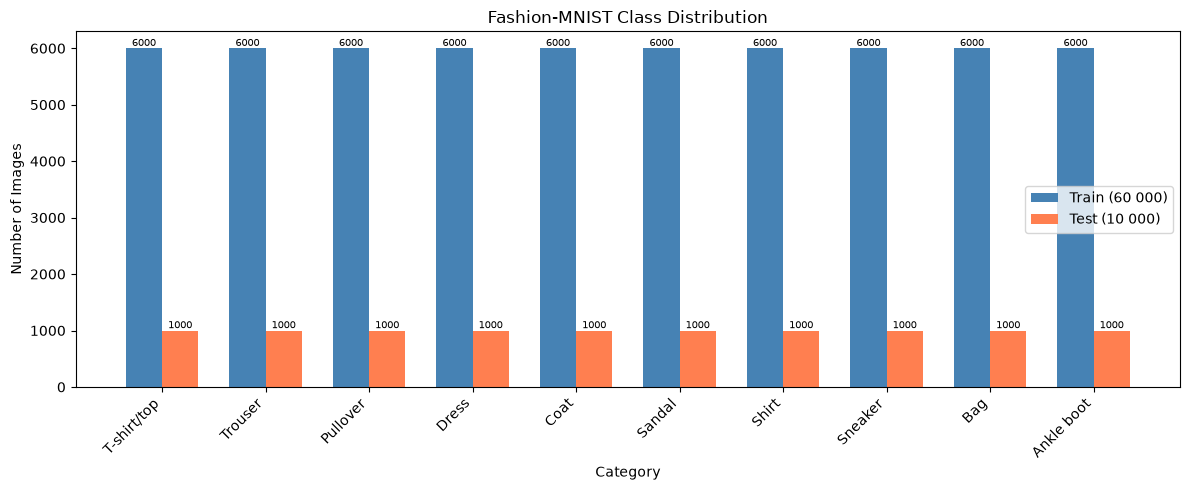

In [9]:
# ============================================================
# 4.4.2  Class Distribution
# ============================================================
train_counts = [np.sum(y_train_raw == i) for i in range(NUM_CLASSES)]
test_counts  = [np.sum(y_test_raw == i) for i in range(NUM_CLASSES)]

x = np.arange(NUM_CLASSES)
width = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, train_counts, width, label='Train (60 000)', color='steelblue')
bars2 = ax.bar(x + width/2, test_counts, width, label='Test (10 000)', color='coral')
ax.set_xlabel('Category')
ax.set_ylabel('Number of Images')
ax.set_title('Fashion-MNIST Class Distribution')
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
ax.legend()
ax.bar_label(bars1, fontsize=7)
ax.bar_label(bars2, fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'class_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

### 4.4.3 One Example Per Category

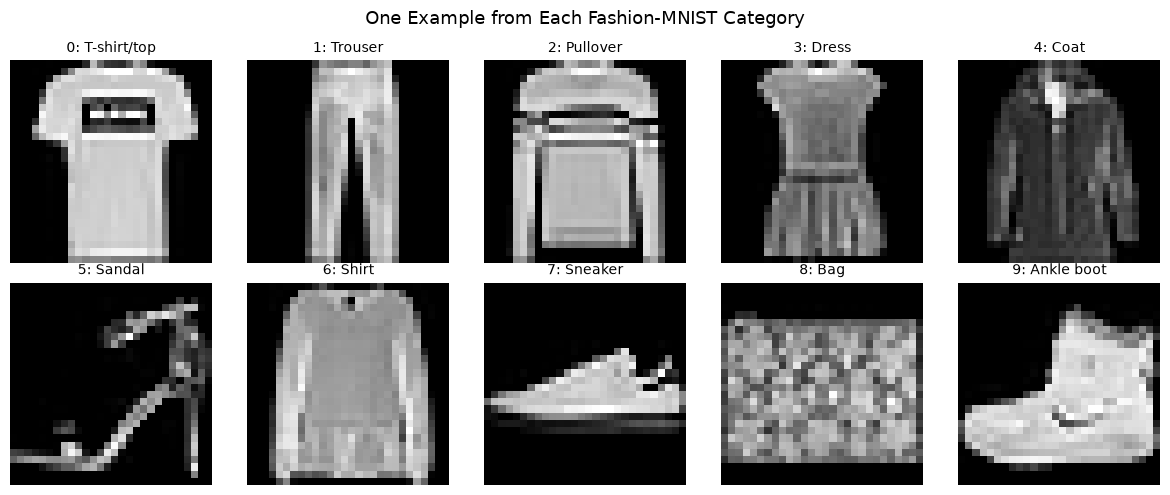

In [10]:
# ============================================================
# 4.4.3  One image per class
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y_train_raw == i)[0][0]
    ax.imshow(X_train_raw[idx], cmap='gray')
    ax.set_title(f"{i}: {CLASS_NAMES[i]}", fontsize=10)
    ax.axis('off')
fig.suptitle('One Example from Each Fashion-MNIST Category', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'one_per_class.png'), dpi=150, bbox_inches='tight')
plt.show()

### 4.4.4 Dataset Summary Table

In [11]:
# ============================================================
# 4.4.4  Summary Table
# ============================================================
summary = pd.DataFrame({
    'Property': [
        'Total images', 'Training images', 'Test images',
        'Image height', 'Image width', 'Channels',
        'Pixel range', 'Data type', 'Number of classes'
    ],
    'Value': [
        '70,000', '60,000', '10,000',
        '28 px', '28 px', '1 (grayscale)',
        '[0, 255]', str(X_train_raw.dtype), '10'
    ]
})
display(summary.style.hide(axis='index').set_caption('Fashion-MNIST Dataset Summary'))

Property,Value
Total images,"70,000"
Training images,"60,000"
Test images,"10,000"
Image height,28 px
Image width,28 px
Channels,1 (grayscale)
Pixel range,"[0, 255]"
Data type,uint8
Number of classes,10


---
# 5. Data Preprocessing

Different models require different input formats. This section prepares **four versions**
of the data:

| Model | Input shape | Value range | Notes |
|-------|-------------|-------------|-------|
| MLP | (N, 784) | [0, 1] float32 | Flattened |
| CNN | (N, 28, 28, 1) | [0, 1] float32 | Channel dimension added |
| SOM | (N, 784) | [0, 1] float32 | Same as MLP; subset |
| ART1 | (N, 784) | {0, 1} binary | Thresholded; small subset |

In [12]:
# ============================================================
# 5.1  Normalize to [0, 1] float32
# ============================================================
X_train_norm = X_train_raw.astype(np.float32) / 255.0
X_test_norm  = X_test_raw.astype(np.float32)  / 255.0
print(f"Normalized pixel range: [{X_train_norm.min()}, {X_train_norm.max()}]")

Normalized pixel range: [0.0, 1.0]


In [13]:
# ============================================================
# 5.2  Flatten for MLP  (N, 784)
# ============================================================
X_train_flat = X_train_norm.reshape(-1, IMG_PIXELS)
X_test_flat  = X_test_norm.reshape(-1, IMG_PIXELS)
print(f"MLP train shape: {X_train_flat.shape}")
print(f"MLP test  shape: {X_test_flat.shape}")

MLP train shape: (60000, 784)
MLP test  shape: (10000, 784)


In [14]:
# ============================================================
# 5.3  Reshape for CNN  (N, 28, 28, 1)
# ============================================================
X_train_cnn = X_train_norm.reshape(-1, IMG_HEIGHT, IMG_WIDTH, 1)
X_test_cnn  = X_test_norm.reshape(-1, IMG_HEIGHT, IMG_WIDTH, 1)
print(f"CNN train shape: {X_train_cnn.shape}")
print(f"CNN test  shape: {X_test_cnn.shape}")

CNN train shape: (60000, 28, 28, 1)
CNN test  shape: (10000, 28, 28, 1)


In [15]:
# ============================================================
# 5.4  Stratified Train / Validation Split
# ============================================================
# We split the 60 000 training images into ~54 000 train + ~6 000 validation.
# The official 10 000 test images remain untouched.

(X_train_mlp, X_val_mlp,
 y_train_mlp, y_val_mlp) = train_test_split(
    X_train_flat, y_train_raw,
    test_size=VAL_FRACTION, stratify=y_train_raw, random_state=SEED
)

(X_train_cnn_split, X_val_cnn,
 y_train_cnn, y_val_cnn) = train_test_split(
    X_train_cnn, y_train_raw,
    test_size=VAL_FRACTION, stratify=y_train_raw, random_state=SEED
)

print(f"MLP  — train: {X_train_mlp.shape}, val: {X_val_mlp.shape}")
print(f"CNN  — train: {X_train_cnn_split.shape}, val: {X_val_cnn.shape}")
print(f"Test — {X_test_flat.shape[0]} images (held out)")

MLP  — train: (54000, 784), val: (6000, 784)
CNN  — train: (54000, 28, 28, 1), val: (6000, 28, 28, 1)
Test — 10000 images (held out)


## 5.5 SOM Data Preparation

SOM uses the normalized 784-dimensional vectors. We take a reproducible subset of the
training data to keep computation manageable.

In [16]:
# ============================================================
# 5.5  SOM Subset
# ============================================================
rng_som = np.random.RandomState(SEED)
som_indices = rng_som.choice(len(X_train_flat), size=min(SOM_SUBSET, len(X_train_flat)),
                              replace=False)
X_som_train  = X_train_flat[som_indices]
y_som_train  = y_train_raw[som_indices]   # Labels — used ONLY for evaluation, not training
print(f"SOM training subset: {X_som_train.shape}")

SOM training subset: (10000, 784)


## 5.6 ART1 Data Preparation

ART1 requires **binary** input patterns. We convert each pixel to 0 or 1 using a
threshold (default 0.5). This discards grayscale detail but produces the crisp binary
vectors that ART1 was designed for.

In [17]:
# ============================================================
# 5.6  Binarize for ART1
# ============================================================
X_train_bin = (X_train_flat > ART1_BIN_THRESHOLD).astype(np.float32)
X_test_bin  = (X_test_flat  > ART1_BIN_THRESHOLD).astype(np.float32)

# Take subsets
rng_art = np.random.RandomState(SEED)
art_train_idx = rng_art.choice(len(X_train_bin), size=ART1_TRAIN_SUBSET, replace=False)
art_eval_idx  = rng_art.choice(len(X_test_bin),  size=ART1_EVAL_SUBSET,  replace=False)

X_art_train = X_train_bin[art_train_idx]
y_art_train = y_train_raw[art_train_idx]   # ONLY for evaluation

X_art_eval  = X_test_bin[art_eval_idx]
y_art_eval  = y_test_raw[art_eval_idx]     # ONLY for evaluation

print(f"ART1 train subset : {X_art_train.shape}  (binary)")
print(f"ART1 eval  subset : {X_art_eval.shape}   (binary)")
print(f"Non-zero fraction : {X_art_train.mean():.3f}")

ART1 train subset : (1500, 784)  (binary)
ART1 eval  subset : (1000, 784)   (binary)
Non-zero fraction : 0.311


### 5.6.1 Visual Comparison — Grayscale vs. Binary

Below we show the same image before and after binarization to illustrate the information
loss. The binary image retains the overall shape but loses shading gradients.

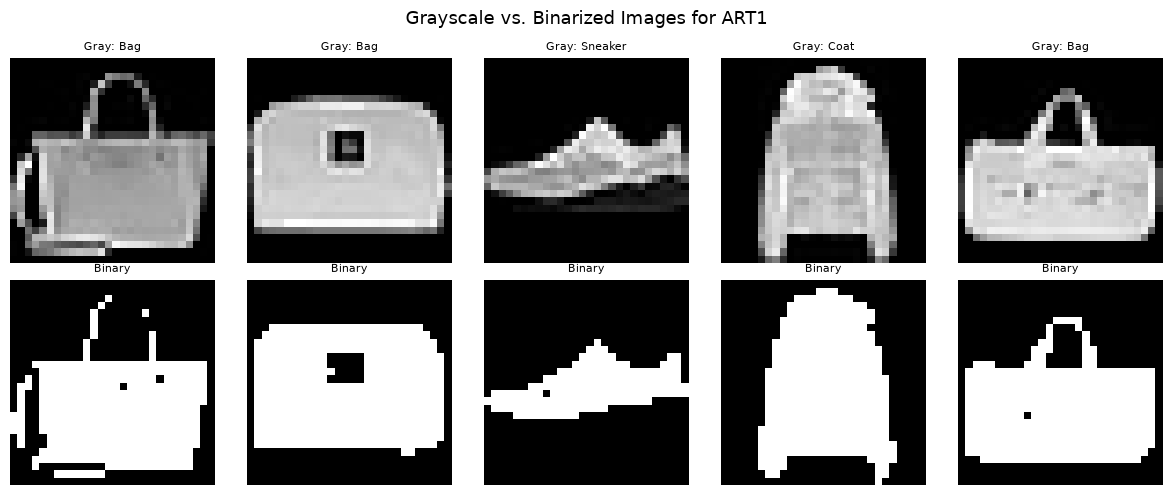

In [18]:
# ============================================================
# 5.6.1  Grayscale vs. Binary Comparison
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(5):
    idx = art_train_idx[i]
    # Grayscale
    axes[0, i].imshow(X_train_norm[idx], cmap='gray')
    axes[0, i].set_title(f"Gray: {CLASS_NAMES[y_train_raw[idx]]}", fontsize=8)
    axes[0, i].axis('off')
    # Binary
    axes[1, i].imshow(X_train_bin[idx].reshape(28, 28), cmap='gray')
    axes[1, i].set_title("Binary", fontsize=8)
    axes[1, i].axis('off')
axes[0, 0].set_ylabel('Grayscale', fontsize=10)
axes[1, 0].set_ylabel('Binary', fontsize=10)
fig.suptitle('Grayscale vs. Binarized Images for ART1', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'gray_vs_binary.png'), dpi=150, bbox_inches='tight')
plt.show()

---
# 6. Model 1 — Multilayer Perceptron (MLP)

## 6.1 What Is an MLP?

A **Multilayer Perceptron** is the simplest form of a deep feed-forward neural network.
It consists of:

- **Input layer:** Receives the flattened image as a 784-element vector.
- **Hidden layers:** One or more layers of *neurons* (also called *units*) that learn
  increasingly abstract representations of the input.
- **Output layer:** Produces a probability distribution over the 10 classes.

Each neuron computes:
$$z = \mathbf{w}^T \mathbf{x} + b$$
$$a = f(z)$$

where $\mathbf{w}$ are the weights, $b$ is the bias, $\mathbf{x}$ is the input vector,
and $f$ is the activation function.

### Key Concepts

| Concept | Explanation |
|---------|-------------|
| **Weights & biases** | Learnable parameters that scale inputs and shift activations |
| **ReLU** | $f(z) = \max(0, z)$ — introduces non-linearity, fast to compute |
| **Softmax** | $\sigma(z_i) = e^{z_i} / \sum_j e^{z_j}$ — converts logits to probabilities summing to 1 |
| **Cross-entropy loss** | $L = -\sum_c y_c \log(\hat{y}_c)$ — measures how far predicted probabilities are from true labels |
| **Backpropagation** | Computes gradients of the loss with respect to each weight using the chain rule |
| **Adam optimizer** | Adaptive learning-rate optimizer combining momentum and RMSProp |
| **Dropout** | Randomly sets a fraction of activations to zero during training to reduce overfitting |
| **Early stopping** | Stops training when validation loss stops improving, then restores the best weights |

### Why 28×28 becomes 784

An MLP expects a one-dimensional input vector. We *flatten* the 28×28 pixel grid into a
single vector of 784 values. This discards spatial (2-D) relationships between pixels —
the MLP treats pixel 0 and pixel 783 the same way, regardless of their positions in the
image.

### Architecture

```
Input (784) → Dense(256, ReLU) → Dropout(0.20) → Dense(128, ReLU) → Dense(10, softmax)
```

## 6.2 MLP Implementation

In [19]:
# ============================================================
# 6.2  Build the MLP Model
# ============================================================
mlp_model = keras.Sequential([
    layers.Input(shape=(IMG_PIXELS,), name='input_flat'),
    layers.Dense(256, activation='relu', name='hidden_1'),
    layers.Dropout(0.20, name='dropout_1'),
    layers.Dense(128, activation='relu', name='hidden_2'),
    layers.Dense(NUM_CLASSES, activation='softmax', name='output')
], name='MLP_Classifier')

mlp_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=MLP_LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mlp_model.summary()

Model: "MLP_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Line-by-Line Explanation

1. **`keras.Sequential([...])`** — creates a linear stack of layers.
2. **`layers.Input(shape=(784,))`** — specifies the input shape (flattened image).
3. **`layers.Dense(256, activation='relu')`** — fully connected layer with 256 neurons
   and ReLU activation.  Parameters: 784 × 256 + 256 = 200,960.
4. **`layers.Dropout(0.20)`** — during training, randomly drops 20% of outputs from the
   previous layer to prevent overfitting.
5. **`layers.Dense(128, activation='relu')`** — second hidden layer (128 neurons).
6. **`layers.Dense(10, activation='softmax')`** — output layer producing 10 class
   probabilities.
7. **`compile(...)`** — configures the training procedure:
   - `Adam(lr=0.001)` — adaptive optimizer.
   - `sparse_categorical_crossentropy` — loss function for integer labels.
   - `accuracy` — metric to monitor.

In [20]:
# ============================================================
# 6.3  Train the MLP
# ============================================================
mlp_callbacks = [
    callbacks.EarlyStopping(
        monitor='val_loss', patience=3,
        restore_best_weights=True, verbose=1
    )
]

print("Training MLP...")
t0 = time.time()
mlp_history = mlp_model.fit(
    X_train_mlp, y_train_mlp,
    validation_data=(X_val_mlp, y_val_mlp),
    epochs=MLP_EPOCHS,
    batch_size=MLP_BATCH,
    callbacks=mlp_callbacks,
    verbose=1
)
mlp_train_time = time.time() - t0
print(f"\nMLP training complete in {mlp_train_time:.1f} seconds.")

Training MLP...
Epoch 1/15


  1/422 ━━━━━━━━━━━━━━━━━━━━ 5:34 795ms/step - accuracy: 0.0625 - loss: 2.4365

 12/422 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4785 - loss: 1.5357    

 25/422 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5819 - loss: 1.2059

 38/422 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6328 - loss: 1.0500

...

414/422 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9014 - loss: 0.2624

422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9017 - loss: 0.2618 - val_accuracy: 0.8965 - val_loss: 0.2987


Epoch 11: early stopping


Restoring model weights from the end of the best epoch: 8.



MLP training complete in 24.5 seconds.


In [21]:
# ============================================================
# 6.4  Save MLP Model
# ============================================================
mlp_save_path = os.path.join(MODELS_DIR, 'mlp_fashion.keras')
mlp_model.save(mlp_save_path)
print(f"MLP model saved to {mlp_save_path}")

MLP model saved to models\mlp_fashion.keras


## 6.5 MLP Learning Curves

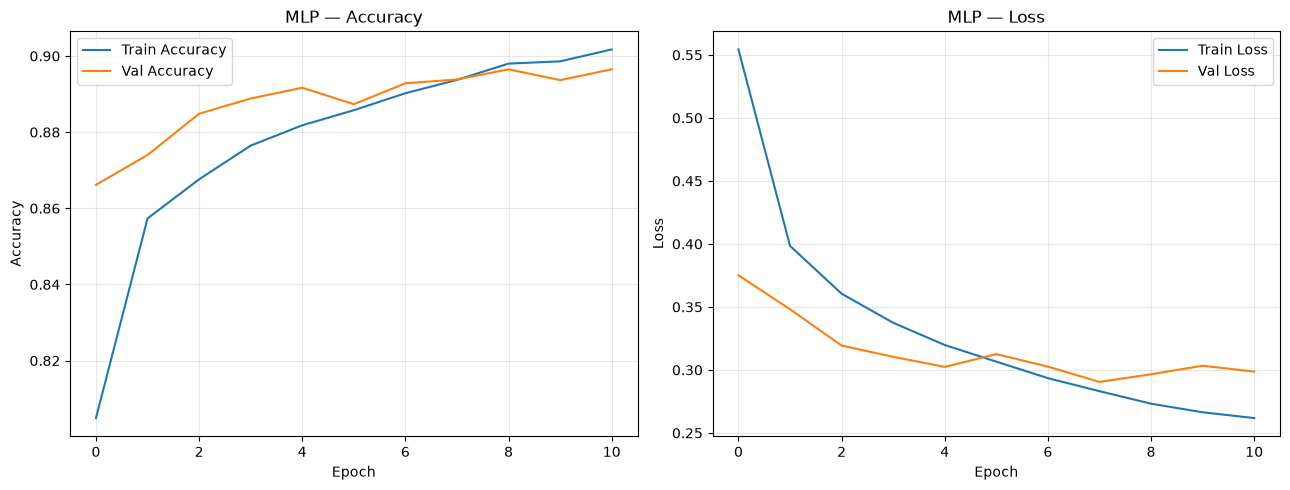

In [22]:
# ============================================================
# 6.5  MLP Learning Curves
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(mlp_history.history['accuracy'],     label='Train Accuracy')
ax1.plot(mlp_history.history['val_accuracy'],  label='Val Accuracy')
ax1.set_title('MLP — Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(mlp_history.history['loss'],     label='Train Loss')
ax2.plot(mlp_history.history['val_loss'],  label='Val Loss')
ax2.set_title('MLP — Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'mlp_learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6.6 MLP Evaluation on Test Set

In [23]:
# ============================================================
# 6.6  MLP Test Evaluation
# ============================================================
# Predictions
t0 = time.time()
mlp_probs = mlp_model.predict(X_test_flat, verbose=0)
mlp_inference_time = time.time() - t0
mlp_preds = np.argmax(mlp_probs, axis=1)

# Metrics
mlp_test_acc  = accuracy_score(y_test_raw, mlp_preds)
mlp_f1        = f1_score(y_test_raw, mlp_preds, average='macro')
mlp_precision = precision_score(y_test_raw, mlp_preds, average='macro')
mlp_recall    = recall_score(y_test_raw, mlp_preds, average='macro')

print("=" * 55)
print("MLP TEST RESULTS")
print("=" * 55)
print(f"Test Accuracy    : {mlp_test_acc:.4f}")
print(f"Macro Precision  : {mlp_precision:.4f}")
print(f"Macro Recall     : {mlp_recall:.4f}")
print(f"Macro F1-Score   : {mlp_f1:.4f}")
print(f"Inference time   : {mlp_inference_time:.3f} s  ({len(X_test_flat)} images)")
print(f"Trainable params : {mlp_model.count_params():,}")
print("-" * 55)
print("\nClassification Report:\n")
print(classification_report(y_test_raw, mlp_preds, target_names=CLASS_NAMES))

MLP TEST RESULTS
Test Accuracy    : 0.8806
Macro Precision  : 0.8806
Macro Recall     : 0.8806
Macro F1-Score   : 0.8799
Inference time   : 0.737 s  (10000 images)
Trainable params : 235,146
-------------------------------------------------------

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top       0.81      0.88      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.77      0.81      0.79      1000
       Dress       0.88      0.89      0.88      1000
        Coat       0.79      0.80      0.79      1000
      Sandal       0.98      0.94      0.96      1000
       Shirt       0.73      0.63      0.68      1000
     Sneaker       0.92      0.97      0.94      1000
         Bag       0.98      0.96      0.97      1000
  Ankle boot       0.95      0.94      0.95      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88 

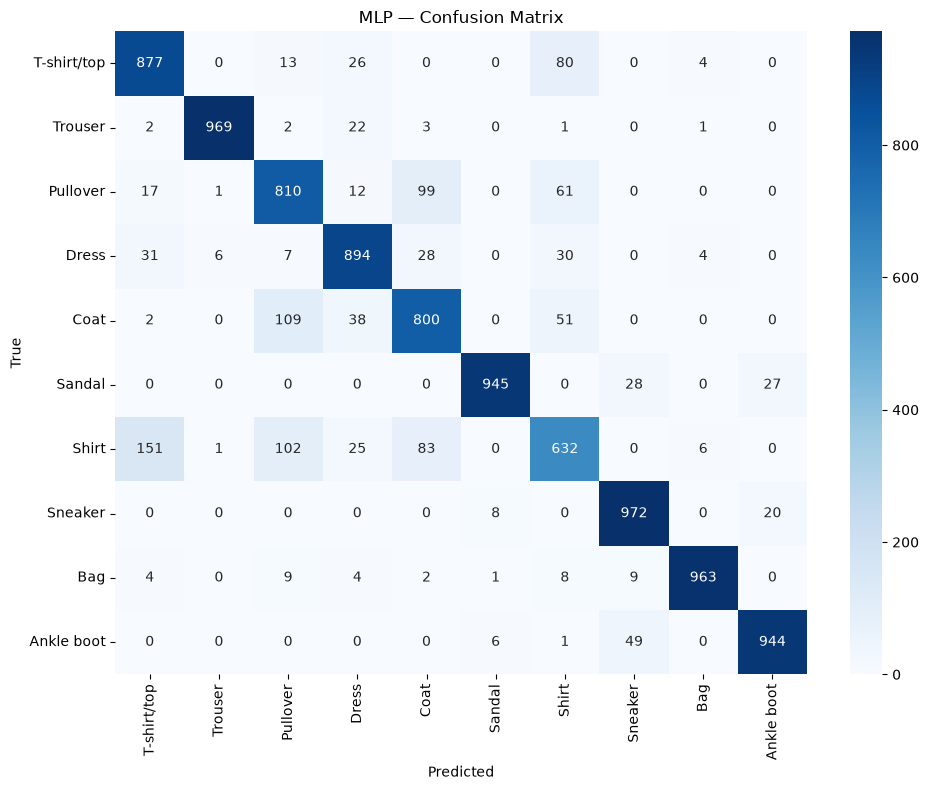

In [24]:
# ============================================================
# 6.7  MLP Confusion Matrix
# ============================================================
cm_mlp = confusion_matrix(y_test_raw, mlp_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('MLP — Confusion Matrix')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'confusion_matrix_mlp.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6.8 MLP Sample Predictions

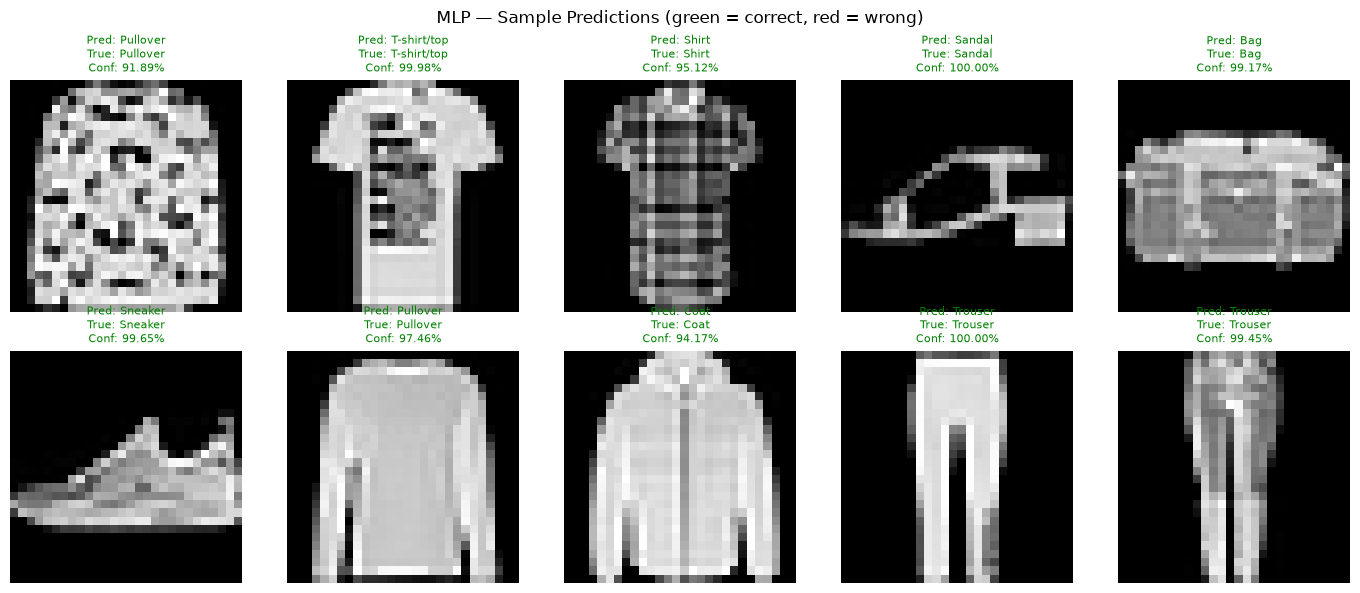

In [25]:
# ============================================================
# 6.8  MLP Sample Predictions with Confidence
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
sample_idx = np.random.choice(len(X_test_raw), 10, replace=False)
for ax, idx in zip(axes.ravel(), sample_idx):
    ax.imshow(X_test_raw[idx], cmap='gray')
    pred_class = mlp_preds[idx]
    true_class = y_test_raw[idx]
    confidence = mlp_probs[idx][pred_class]
    colour = 'green' if pred_class == true_class else 'red'
    ax.set_title(f"Pred: {CLASS_NAMES[pred_class]}\nTrue: {CLASS_NAMES[true_class]}\n"
                 f"Conf: {confidence:.2%}", fontsize=8, color=colour)
    ax.axis('off')
fig.suptitle('MLP — Sample Predictions (green = correct, red = wrong)', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'mlp_sample_preds.png'), dpi=150, bbox_inches='tight')
plt.show()

---
# 7. Model 2 — Convolutional Neural Network (CNN)

## 7.1 What Is a CNN?

A **Convolutional Neural Network** is designed specifically for grid-structured data like
images. Unlike the MLP, which flattens the image and ignores spatial relationships, a CNN
preserves the 2-D structure and learns *local spatial features* through convolutional
filters.

### Key Components

| Component | Purpose |
|-----------|---------|
| **Convolution layer** | Slides small filters (kernels) across the image to detect features (edges, textures, shapes) |
| **Filter / Kernel** | A small learnable weight matrix (e.g., 3×3) that detects one type of feature |
| **Feature map** | The output of applying one filter across the entire image |
| **Stride** | How many pixels the filter moves at each step (usually 1) |
| **Padding ('same')** | Adds zeros around the image border so the output has the same spatial dimensions |
| **ReLU** | Non-linear activation applied element-wise after convolution |
| **Max Pooling** | Downsamples by taking the maximum value in each 2×2 window — reduces spatial size and computation |
| **Flatten** | Converts the final 2-D feature maps into a 1-D vector for the fully connected layers |
| **Dense + Softmax** | Classification head — same as in MLP |

### How Convolution Works

A 3×3 filter slides over the 28×28 image. At each position, the filter computes a
weighted sum of the 9 pixels it covers:

$$\text{output}(i, j) = \sum_{m}\sum_{n} \text{filter}(m, n) \cdot \text{input}(i+m,\, j+n) + \text{bias}$$

With **32 filters**, the first convolution layer produces 32 feature maps, each
highlighting a different pattern. The second layer (64 filters) combines these lower-level
features into higher-level representations.

### Architecture

```
Input (28×28×1)
 → Conv2D(32, 3×3, ReLU, same)  → output: 28×28×32
 → MaxPool(2×2)                 → output: 14×14×32
 → Conv2D(64, 3×3, ReLU, same)  → output: 14×14×64
 → MaxPool(2×2)                 → output: 7×7×64
 → Flatten                      → output: 3136
 → Dense(128, ReLU)
 → Dropout(0.30)
 → Dense(10, softmax)
```

### Why CNN May Outperform MLP on Images

The MLP treats each pixel independently. The CNN groups nearby pixels using convolution,
learning *spatial patterns* like edges and corners. This inductive bias usually improves
accuracy on image tasks — but the actual performance depends on the dataset and must be
measured experimentally.

In [26]:
# ============================================================
# 7.2  Build the CNN Model
# ============================================================
cnn_model = keras.Sequential([
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1), name='input_img'),

    layers.Conv2D(32, (3, 3), activation='relu', padding='same', name='conv1'),
    layers.MaxPooling2D((2, 2), name='pool1'),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
    layers.MaxPooling2D((2, 2), name='pool2'),

    layers.Flatten(name='flatten'),
    layers.Dense(128, activation='relu', name='fc1'),
    layers.Dropout(0.30, name='dropout'),
    layers.Dense(NUM_CLASSES, activation='softmax', name='output')
], name='CNN_Classifier')

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CNN_LR),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

cnn_model.summary()

Model: "CNN_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1 (Conv2D)                  │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

### Layer-by-Layer Shape Table

| Layer | Output Shape | Parameters |
|-------|-------------|------------|
| Input | (None, 28, 28, 1) | 0 |
| Conv2D (32 filters, 3×3) | (None, 28, 28, 32) | (3×3×1+1)×32 = 320 |
| MaxPool (2×2) | (None, 14, 14, 32) | 0 |
| Conv2D (64 filters, 3×3) | (None, 14, 14, 64) | (3×3×32+1)×64 = 18,496 |
| MaxPool (2×2) | (None, 7, 7, 64) | 0 |
| Flatten | (None, 3136) | 0 |
| Dense (128, ReLU) | (None, 128) | 3136×128+128 = 401,536 |
| Dropout (0.30) | (None, 128) | 0 |
| Dense (10, softmax) | (None, 10) | 128×10+10 = 1,290 |

In [27]:
# ============================================================
# 7.3  Train the CNN
# ============================================================
cnn_callbacks = [
    callbacks.EarlyStopping(
        monitor='val_loss', patience=3,
        restore_best_weights=True, verbose=1
    )
]

print("Training CNN...")
t0 = time.time()
cnn_history = cnn_model.fit(
    X_train_cnn_split, y_train_cnn,
    validation_data=(X_val_cnn, y_val_cnn),
    epochs=CNN_EPOCHS,
    batch_size=CNN_BATCH,
    callbacks=cnn_callbacks,
    verbose=1
)
cnn_train_time = time.time() - t0
print(f"\nCNN training complete in {cnn_train_time:.1f} seconds.")

Training CNN...
Epoch 1/15


  1/422 ━━━━━━━━━━━━━━━━━━━━ 5:46 823ms/step - accuracy: 0.0547 - loss: 2.3299

  3/422 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - accuracy: 0.1745 - loss: 2.2429  

  6/422 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.2747 - loss: 2.1114 

  9/422 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.3411 - loss: 1.9684

...

421/422 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9477 - loss: 0.1401

422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.9477 - loss: 0.1402 - val_accuracy: 0.9240 - val_loss: 0.2207


Epoch 12: early stopping


Restoring model weights from the end of the best epoch: 9.



CNN training complete in 167.8 seconds.


In [28]:
# ============================================================
# 7.4  Save CNN Model
# ============================================================
cnn_save_path = os.path.join(MODELS_DIR, 'cnn_fashion.keras')
cnn_model.save(cnn_save_path)
print(f"CNN model saved to {cnn_save_path}")

CNN model saved to models\cnn_fashion.keras


## 7.5 CNN Learning Curves

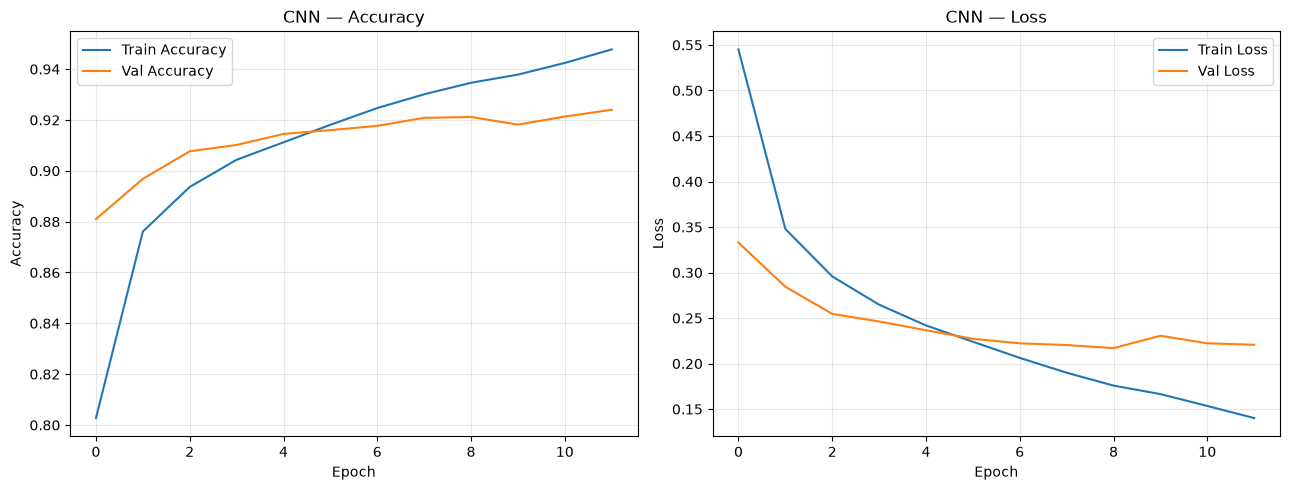

In [29]:
# ============================================================
# 7.5  CNN Learning Curves
# ============================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(cnn_history.history['accuracy'],     label='Train Accuracy')
ax1.plot(cnn_history.history['val_accuracy'],  label='Val Accuracy')
ax1.set_title('CNN — Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(cnn_history.history['loss'],     label='Train Loss')
ax2.plot(cnn_history.history['val_loss'],  label='Val Loss')
ax2.set_title('CNN — Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'cnn_learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7.6 CNN Evaluation on Test Set

In [30]:
# ============================================================
# 7.6  CNN Test Evaluation
# ============================================================
t0 = time.time()
cnn_probs = cnn_model.predict(X_test_cnn, verbose=0)
cnn_inference_time = time.time() - t0
cnn_preds = np.argmax(cnn_probs, axis=1)

cnn_test_acc  = accuracy_score(y_test_raw, cnn_preds)
cnn_f1        = f1_score(y_test_raw, cnn_preds, average='macro')
cnn_precision = precision_score(y_test_raw, cnn_preds, average='macro')
cnn_recall    = recall_score(y_test_raw, cnn_preds, average='macro')

print("=" * 55)
print("CNN TEST RESULTS")
print("=" * 55)
print(f"Test Accuracy    : {cnn_test_acc:.4f}")
print(f"Macro Precision  : {cnn_precision:.4f}")
print(f"Macro Recall     : {cnn_recall:.4f}")
print(f"Macro F1-Score   : {cnn_f1:.4f}")
print(f"Inference time   : {cnn_inference_time:.3f} s  ({len(X_test_cnn)} images)")
print(f"Trainable params : {cnn_model.count_params():,}")
print("-" * 55)
print("\nClassification Report:\n")
print(classification_report(y_test_raw, cnn_preds, target_names=CLASS_NAMES))

CNN TEST RESULTS
Test Accuracy    : 0.9105
Macro Precision  : 0.9120
Macro Recall     : 0.9105
Macro F1-Score   : 0.9108
Inference time   : 3.214 s  (10000 images)
Trainable params : 421,642
-------------------------------------------------------

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top       0.87      0.86      0.87      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.85      0.89      0.87      1000
       Dress       0.91      0.92      0.92      1000
        Coat       0.88      0.83      0.85      1000
      Sandal       0.99      0.98      0.99      1000
       Shirt       0.73      0.76      0.75      1000
     Sneaker       0.91      0.99      0.95      1000
         Bag       0.99      0.98      0.98      1000
  Ankle boot       0.99      0.92      0.95      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91 

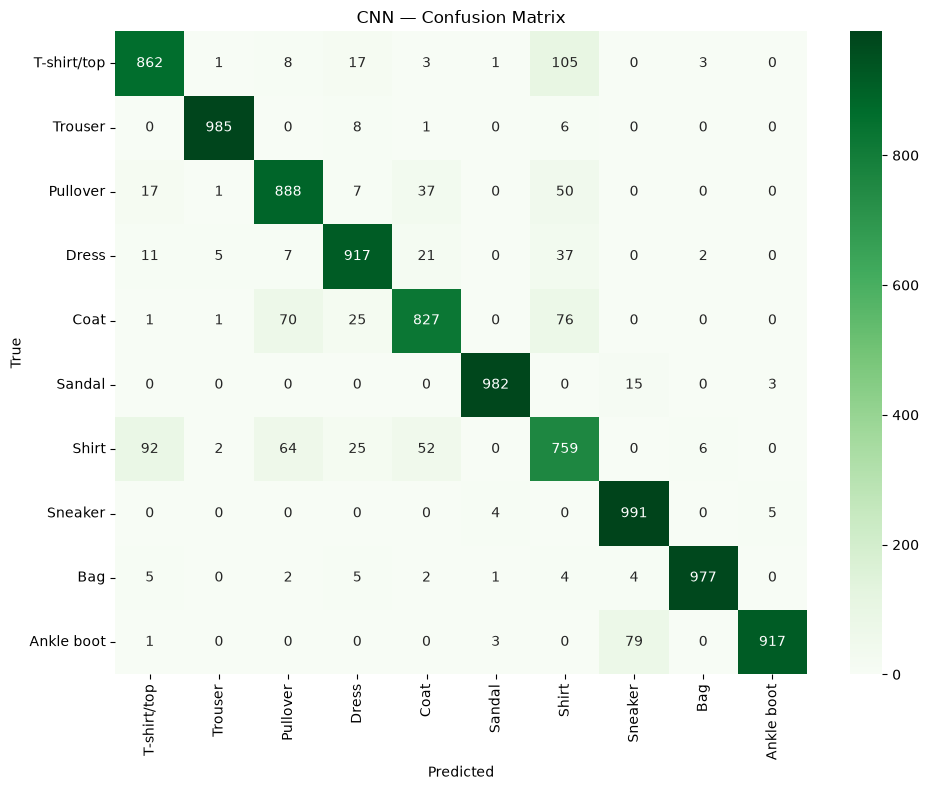

In [31]:
# ============================================================
# 7.7  CNN Confusion Matrix
# ============================================================
cm_cnn = confusion_matrix(y_test_raw, cnn_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('CNN — Confusion Matrix')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'confusion_matrix_cnn.png'), dpi=150, bbox_inches='tight')
plt.show()

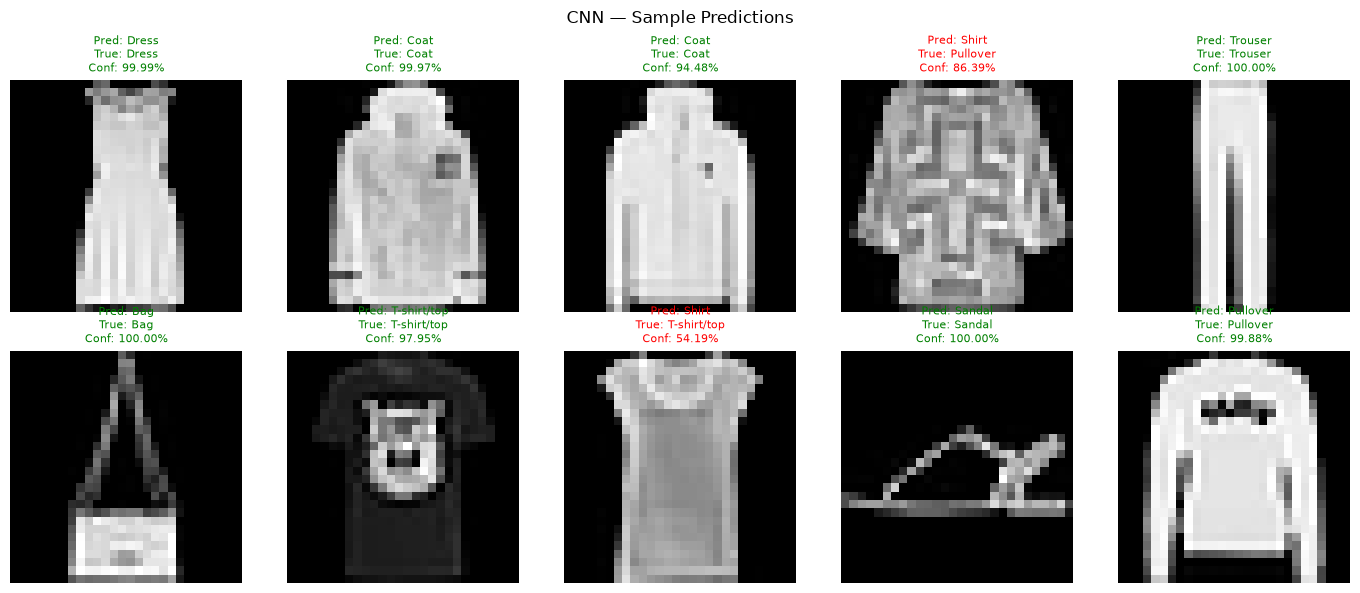

In [32]:
# ============================================================
# 7.8  CNN Sample Predictions
# ============================================================
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
sample_idx = np.random.choice(len(X_test_raw), 10, replace=False)
for ax, idx in zip(axes.ravel(), sample_idx):
    ax.imshow(X_test_raw[idx], cmap='gray')
    pred_class = cnn_preds[idx]
    true_class = y_test_raw[idx]
    confidence = cnn_probs[idx][pred_class]
    colour = 'green' if pred_class == true_class else 'red'
    ax.set_title(f"Pred: {CLASS_NAMES[pred_class]}\nTrue: {CLASS_NAMES[true_class]}\n"
                 f"Conf: {confidence:.2%}", fontsize=8, color=colour)
    ax.axis('off')
fig.suptitle('CNN — Sample Predictions', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'cnn_sample_preds.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7.9 CNN Feature Map Visualization

Below we visualize the feature maps (activations) produced by the first convolutional
layer for a single test image. Each feature map highlights a different learned pattern.

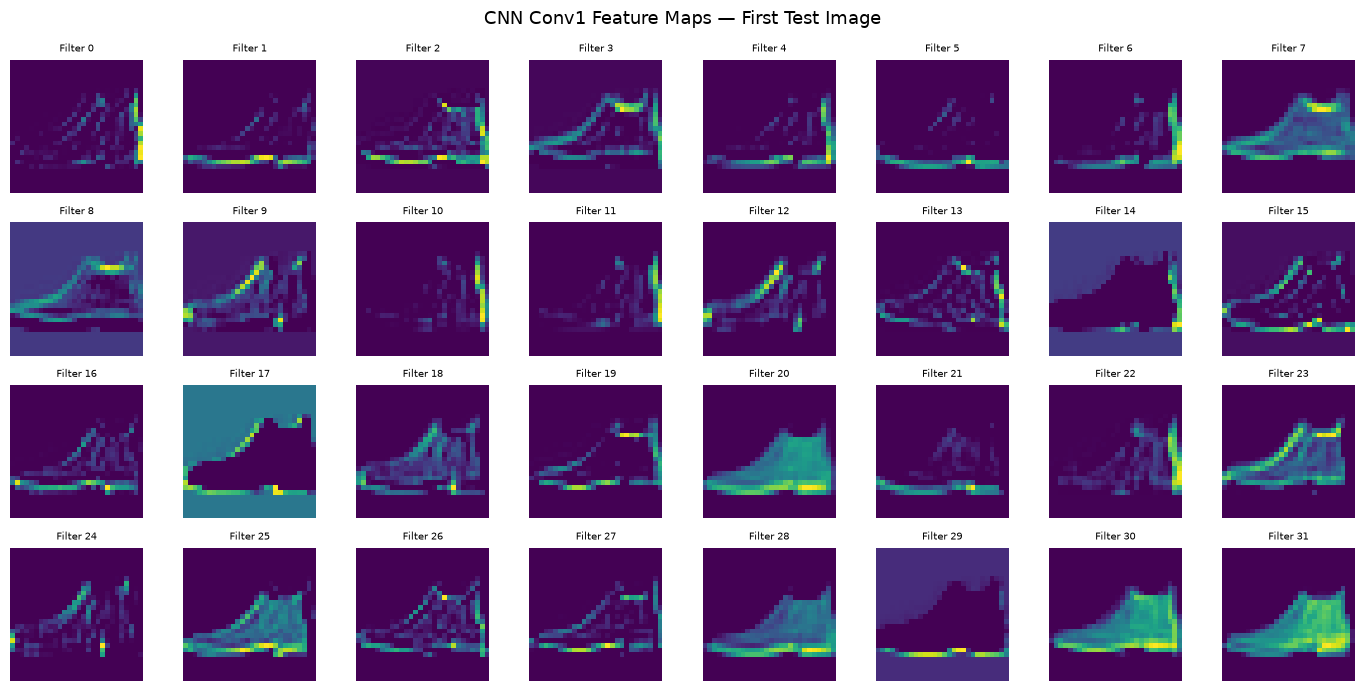

In [33]:
# ============================================================
# 7.9  Feature Map Visualization
# ============================================================
# Build a sub-model that outputs the first conv layer's activations
feat_model = keras.Model(
    inputs=cnn_model.inputs[0],
    outputs=cnn_model.get_layer('conv1').output
)

sample_img = X_test_cnn[0:1]  # shape (1, 28, 28, 1)
feature_maps = feat_model.predict(sample_img, verbose=0)  # (1, 28, 28, 32)

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[0, :, :, i], cmap='viridis')
    ax.set_title(f'Filter {i}', fontsize=7)
    ax.axis('off')
fig.suptitle('CNN Conv1 Feature Maps — First Test Image', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'cnn_feature_maps.png'), dpi=150, bbox_inches='tight')
plt.show()

---
# 8. Model 3 — Self-Organizing Map (SOM)

## 8.1 What Is a SOM?

A **Self-Organizing Map** (also called a *Kohonen map*) is an **unsupervised** neural
network that projects high-dimensional data onto a low-dimensional (typically 2-D) grid
while preserving the *topological* structure of the data.

### How It Works

1. Initialize a grid of neurons, each with a random **prototype weight vector** of the
   same dimension as the input (784).
2. For each training iteration:
   a. Pick a random input sample.
   b. Find the **Best Matching Unit (BMU)** — the neuron whose prototype is closest
      (Euclidean distance) to the input.
   c. Update the BMU and its **neighbours** to become more similar to the input.
   d. The **neighbourhood radius** and **learning rate** shrink over time.
3. After training, nearby neurons represent similar patterns.

### Key Equations

**Euclidean distance:**  
$$d(\mathbf{x}, \mathbf{w}_j) = \sqrt{\sum_{k=1}^{784} (x_k - w_{j,k})^2}$$

**Best Matching Unit:**  
$$\text{BMU} = \arg\min_j \; d(\mathbf{x}, \mathbf{w}_j)$$

**Neighbourhood function (Gaussian):**  
$$h(j, \text{BMU}, t) = \exp\!\left(-\frac{\|\text{pos}_j - \text{pos}_{\text{BMU}}\|^2}{2\,\sigma(t)^2}\right)$$

**Weight update:**  
$$\mathbf{w}_j(t+1) = \mathbf{w}_j(t) + \alpha(t) \cdot h(j, \text{BMU}, t) \cdot (\mathbf{x} - \mathbf{w}_j(t))$$

**Learning rate decay:**  
$$\alpha(t) = \alpha_0 \cdot \exp(-t / \tau_\alpha)$$

**Neighbourhood radius decay:**  
$$\sigma(t) = \sigma_0 \cdot \exp(-t / \tau_\sigma)$$

### Important Notes

- A 10×10 SOM has **100 neurons** — this is *not* the same as a 10-class classifier.
  Multiple neurons may represent the same fashion category, and a single neuron may
  respond to images from more than one category.
- Ground-truth labels are **never** used during SOM weight updates. We use them *only
  afterwards* to evaluate how well the map's clusters align with the known classes.

## 8.2 SOM Implementation

In [34]:
# ============================================================
# 8.2  Self-Organizing Map — NumPy Implementation
# ============================================================

class SelfOrganizingMap:
    """
    A 2-D Self-Organizing Map implemented from scratch with NumPy.

    Parameters
    ----------
    grid_h, grid_w : int
        Height and width of the neuron grid.
    input_dim : int
        Dimensionality of input vectors (784 for flattened 28×28).
    lr_init : float
        Initial learning rate.
    sigma_init : float
        Initial neighbourhood radius (in grid units).
    seed : int
        Random seed for reproducibility.
    """

    def __init__(self, grid_h, grid_w, input_dim,
                 lr_init=0.5, sigma_init=5.0, seed=42):
        self.grid_h    = grid_h
        self.grid_w    = grid_w
        self.input_dim = input_dim
        self.lr_init   = lr_init
        self.sigma_init = sigma_init

        rng = np.random.RandomState(seed)
        # Initialize weights uniformly in [0, 1]
        self.weights = rng.rand(grid_h, grid_w, input_dim).astype(np.float32)

        # Precompute neuron grid positions for neighbourhood calculation
        rows, cols = np.meshgrid(np.arange(grid_h), np.arange(grid_w), indexing='ij')
        self.positions = np.stack([rows, cols], axis=-1)  # (H, W, 2)

        self.history = {'qe': []}  # training history

    def _find_bmu(self, x):
        """Find the Best Matching Unit for input vector x."""
        # x shape: (input_dim,)
        # weights shape: (H, W, input_dim)
        diff = self.weights - x  # broadcast: (H, W, input_dim)
        dists = np.sqrt(np.sum(diff ** 2, axis=2))  # (H, W)
        bmu_idx = np.unravel_index(np.argmin(dists), dists.shape)
        return bmu_idx, dists[bmu_idx]

    def _neighbourhood(self, bmu_pos, sigma):
        """Compute Gaussian neighbourhood values for all neurons."""
        bmu_pos = np.array(bmu_pos)  # (2,)
        diff = self.positions - bmu_pos  # (H, W, 2)
        sq_dist = np.sum(diff ** 2, axis=2)  # (H, W)
        return np.exp(-sq_dist / (2 * sigma ** 2))  # (H, W)

    def train(self, data, n_iterations):
        """
        Train the SOM.

        Parameters
        ----------
        data : ndarray, shape (N, input_dim)
            Training data (labels are NOT used).
        n_iterations : int
            Number of training iterations.
        """
        n_samples = len(data)
        # Time constants for exponential decay
        tau_lr    = n_iterations / np.log(self.lr_init / 0.01 + 1e-8)
        tau_sigma = n_iterations / np.log(self.sigma_init / 0.5 + 1e-8)

        rng = np.random.RandomState(42)

        for t in range(n_iterations):
            # Current learning rate and radius
            lr    = self.lr_init   * np.exp(-t / tau_lr)
            sigma = self.sigma_init * np.exp(-t / tau_sigma)
            sigma = max(sigma, 0.5)  # floor to prevent collapse

            # Pick a random sample
            idx = rng.randint(n_samples)
            x = data[idx]

            # Find BMU
            bmu_pos, bmu_dist = self._find_bmu(x)

            # Neighbourhood
            h = self._neighbourhood(bmu_pos, sigma)  # (H, W)

            # Update weights
            # Expand dimensions for broadcasting: h -> (H, W, 1), x - weights -> (H, W, D)
            influence = (lr * h)[:, :, np.newaxis]  # (H, W, 1)
            self.weights += influence * (x - self.weights)

            # Record quantization error periodically
            if t % max(1, n_iterations // 50) == 0:
                self.history['qe'].append(bmu_dist)

            # Progress reporting
            if (t + 1) % max(1, n_iterations // 5) == 0:
                print(f"  SOM iteration {t+1}/{n_iterations}  |  "
                      f"lr={lr:.4f}  sigma={sigma:.2f}  BMU_dist={bmu_dist:.4f}")

        print("SOM training complete.")

    def map_data(self, data):
        """Assign each sample to its BMU. Returns array of (row, col) tuples."""
        bmus = []
        for x in data:
            bmu_pos, _ = self._find_bmu(x)
            bmus.append(bmu_pos)
        return np.array(bmus)

    def quantization_error(self, data):
        """Average distance from each sample to its BMU prototype."""
        total = 0.0
        for x in data:
            _, dist = self._find_bmu(x)
            total += dist
        return total / len(data)

    def topographic_error(self, data):
        """
        Fraction of samples for which the first and second BMU are NOT
        adjacent on the grid.
        """
        errors = 0
        for x in data:
            diff = self.weights - x
            dists = np.sqrt(np.sum(diff ** 2, axis=2))  # (H, W)
            flat_idx = np.argsort(dists.ravel())
            bmu1 = np.unravel_index(flat_idx[0], dists.shape)
            bmu2 = np.unravel_index(flat_idx[1], dists.shape)
            # Check adjacency (Chebyshev distance ≤ 1)
            if max(abs(bmu1[0] - bmu2[0]), abs(bmu1[1] - bmu2[1])) > 1:
                errors += 1
        return errors / len(data)

print("SOM class defined successfully.")

SOM class defined successfully.


### Code Explanation

- **`__init__`**: Initializes the grid with random weights in [0, 1] and precomputes
  neuron positions for fast neighbourhood calculation.
- **`_find_bmu`**: Computes Euclidean distance from input `x` to every neuron and returns
  the closest one (BMU).
- **`_neighbourhood`**: Applies a Gaussian function centred on the BMU to determine how
  strongly each neuron should be updated.
- **`train`**: Main loop — picks random samples, finds BMU, updates weights with decaying
  learning rate and radius.
- **`map_data`**: After training, assigns each sample to its BMU.
- **`quantization_error`**: Average distance from samples to their BMU — lower is better.
- **`topographic_error`**: Fraction of samples whose two closest neurons are not grid
  neighbours — lower means better topology preservation.

In [35]:
# ============================================================
# 8.3  Train the SOM
# ============================================================
print(f"Training SOM ({SOM_GRID_H}×{SOM_GRID_W} grid, {SOM_ITERATIONS} iterations, "
      f"{len(X_som_train)} samples)...")
print(f"Expected time: ~1-3 minutes on CPU\n")

som = SelfOrganizingMap(
    grid_h=SOM_GRID_H, grid_w=SOM_GRID_W,
    input_dim=IMG_PIXELS,
    lr_init=SOM_LR_INIT,
    sigma_init=SOM_SIGMA_INIT,
    seed=SEED
)

t0 = time.time()
som.train(X_som_train, SOM_ITERATIONS)
som_train_time = time.time() - t0
print(f"\nSOM training time: {som_train_time:.1f} seconds")

Training SOM (10×10 grid, 3000 iterations, 10000 samples)...
Expected time: ~1-3 minutes on CPU

  SOM iteration 600/3000  |  lr=0.2290  sigma=3.16  BMU_dist=5.7390


  SOM iteration 1200/3000  |  lr=0.1047  sigma=1.99  BMU_dist=8.2536
  SOM iteration 1800/3000  |  lr=0.0479  sigma=1.26  BMU_dist=6.2360


  SOM iteration 2400/3000  |  lr=0.0219  sigma=0.79  BMU_dist=4.3909
  SOM iteration 3000/3000  |  lr=0.0100  sigma=0.50  BMU_dist=3.7227
SOM training complete.

SOM training time: 1.0 seconds


In [36]:
# ============================================================
# 8.4  Save SOM Weights
# ============================================================
som_weights_path = os.path.join(MODELS_DIR, 'som_weights.npy')
np.save(som_weights_path, som.weights)
print(f"SOM weights saved to {som_weights_path}")

SOM weights saved to models\som_weights.npy


## 8.5 SOM Visualizations

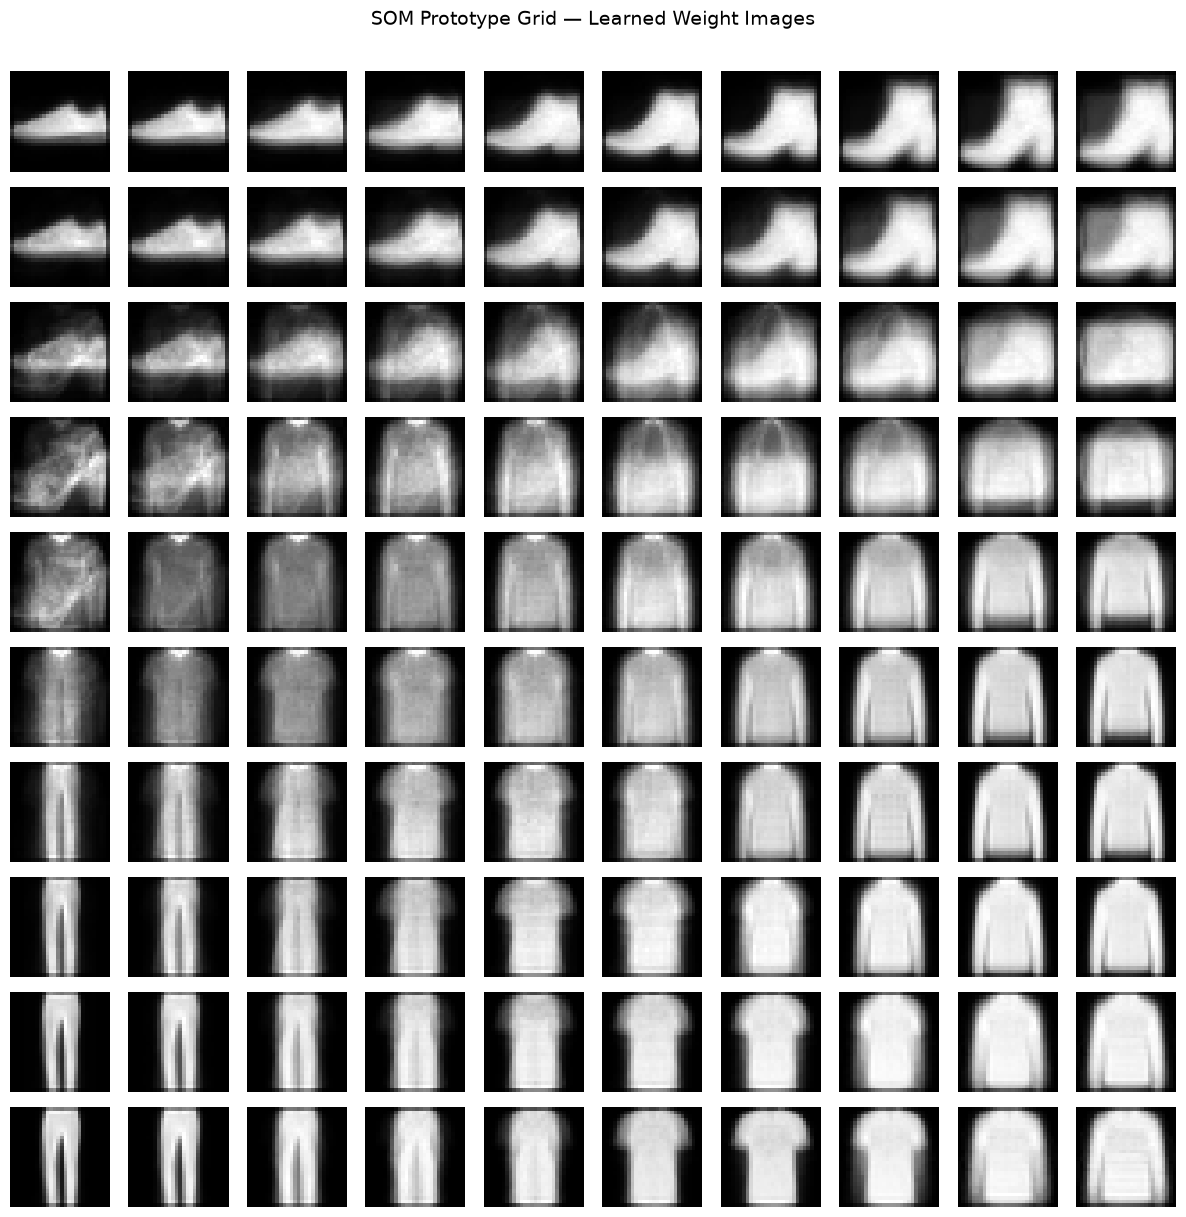

In [37]:
# ============================================================
# 8.5.1  SOM Prototype Grid
# ============================================================
fig, axes = plt.subplots(SOM_GRID_H, SOM_GRID_W,
                          figsize=(SOM_GRID_W * 1.2, SOM_GRID_H * 1.2))
for i in range(SOM_GRID_H):
    for j in range(SOM_GRID_W):
        axes[i, j].imshow(som.weights[i, j].reshape(28, 28), cmap='gray')
        axes[i, j].axis('off')
fig.suptitle('SOM Prototype Grid — Learned Weight Images', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'som_grid.png'), dpi=150, bbox_inches='tight')
plt.show()

Mapping training data to BMUs...


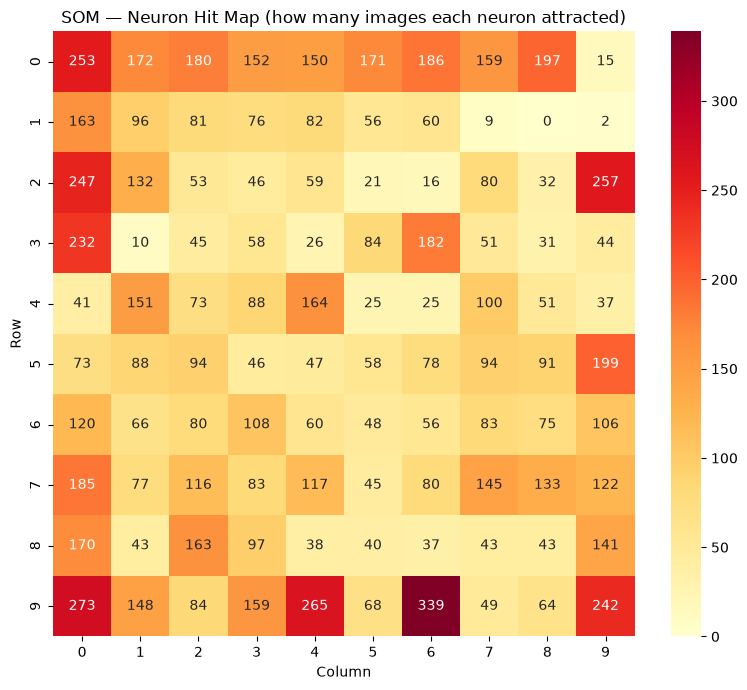

In [38]:
# ============================================================
# 8.5.2  Neuron Hit Map (Occupancy)
# ============================================================
print("Mapping training data to BMUs...")
som_bmus = som.map_data(X_som_train)

hit_map = np.zeros((SOM_GRID_H, SOM_GRID_W), dtype=int)
for bmu in som_bmus:
    hit_map[bmu[0], bmu[1]] += 1

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(hit_map, annot=True, fmt='d', cmap='YlOrRd', ax=ax)
ax.set_title('SOM — Neuron Hit Map (how many images each neuron attracted)')
ax.set_xlabel('Column')
ax.set_ylabel('Row')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'som_hit_map.png'), dpi=150, bbox_inches='tight')
plt.show()

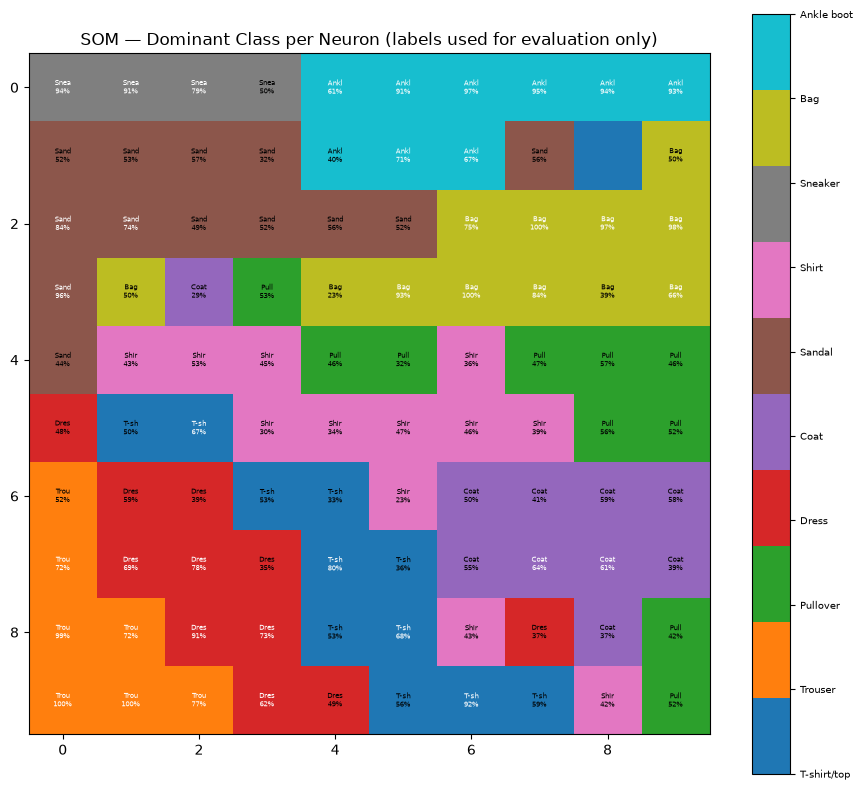

In [39]:
# ============================================================
# 8.5.3  Class Distribution Across Map Cells
# ============================================================
# For each neuron, count how many images of each class mapped to it.
# Labels are used ONLY for evaluation here — they were NOT used during training.

class_map = np.zeros((SOM_GRID_H, SOM_GRID_W, NUM_CLASSES), dtype=int)
for bmu, label in zip(som_bmus, y_som_train):
    class_map[bmu[0], bmu[1], label] += 1

# Dominant class per neuron
dominant_class = np.argmax(class_map, axis=2)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(dominant_class, cmap='tab10', vmin=0, vmax=9)
for i in range(SOM_GRID_H):
    for j in range(SOM_GRID_W):
        total = hit_map[i, j]
        if total > 0:
            dom = dominant_class[i, j]
            purity = class_map[i, j, dom] / total
            ax.text(j, i, f"{CLASS_NAMES[dom][:4]}\n{purity:.0%}",
                    ha='center', va='center', fontsize=5,
                    color='white' if purity > 0.6 else 'black')
ax.set_title('SOM — Dominant Class per Neuron (labels used for evaluation only)')
cbar = fig.colorbar(im, ax=ax, ticks=range(10))
cbar.ax.set_yticklabels(CLASS_NAMES, fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'som_class_map.png'), dpi=150, bbox_inches='tight')
plt.show()

## 8.6 SOM Quantitative Evaluation

In [40]:
# ============================================================
# 8.6  SOM Metrics
# ============================================================
# Use a subset for expensive metrics
eval_subset_size = min(2000, len(X_som_train))
X_som_eval = X_som_train[:eval_subset_size]
y_som_eval = y_som_train[:eval_subset_size]

print("Computing SOM quantization error...")
som_qe = som.quantization_error(X_som_eval)

print("Computing SOM topographic error...")
som_te = som.topographic_error(X_som_eval)

# Cluster labels = BMU flat index
som_bmu_eval = som.map_data(X_som_eval)
som_cluster_labels = som_bmu_eval[:, 0] * SOM_GRID_W + som_bmu_eval[:, 1]

som_ari = adjusted_rand_score(y_som_eval, som_cluster_labels)
som_nmi = normalized_mutual_info_score(y_som_eval, som_cluster_labels)
som_n_clusters = len(np.unique(som_cluster_labels))

print("\n" + "=" * 55)
print("SOM EVALUATION RESULTS")
print("=" * 55)
print(f"Grid size             : {SOM_GRID_H} × {SOM_GRID_W} = {SOM_GRID_H*SOM_GRID_W} neurons")
print(f"Quantization Error    : {som_qe:.4f}")
print(f"Topographic Error     : {som_te:.4f}")
print(f"Occupied neurons      : {som_n_clusters} / {SOM_GRID_H*SOM_GRID_W}")
print(f"Adjusted Rand Index   : {som_ari:.4f}")
print(f"Normalized MI         : {som_nmi:.4f}")
print(f"Training time         : {som_train_time:.1f} s")
print("-" * 55)
print("\nInterpretation:")
print("• QE measures how well prototypes represent the data (lower = better).")
print("• TE measures topology preservation (lower = better).")
print("• ARI and NMI compare discovered clusters to known classes (higher = better).")
print("• A perfect ARI = 1.0 would mean clusters exactly match classes.")
print("  Typical values for unsupervised methods on Fashion-MNIST are 0.3–0.6.")

Computing SOM quantization error...


Computing SOM topographic error...



SOM EVALUATION RESULTS
Grid size             : 10 × 10 = 100 neurons
Quantization Error    : 4.9493
Topographic Error     : 0.0175
Occupied neurons      : 98 / 100
Adjusted Rand Index   : 0.1496
Normalized MI         : 0.4799
Training time         : 1.0 s
-------------------------------------------------------

Interpretation:
• QE measures how well prototypes represent the data (lower = better).
• TE measures topology preservation (lower = better).
• ARI and NMI compare discovered clusters to known classes (higher = better).
• A perfect ARI = 1.0 would mean clusters exactly match classes.
  Typical values for unsupervised methods on Fashion-MNIST are 0.3–0.6.


---
# 9. Model 4 — Adaptive Resonance Theory 1 (ART1)

## 9.1 What Is ART1?

**Adaptive Resonance Theory 1** (Carpenter & Grossberg, 1987) is a classical unsupervised
neural network designed for **binary** pattern classification. It addresses the
**stability–plasticity dilemma**: how can a network learn new patterns (plasticity) without
forgetting previously learned ones (stability)?

### Architecture

ART1 has two layers:
- **F1 (Input field):** Receives the binary input pattern.
- **F2 (Category field):** Contains category nodes, each with learned prototypes.

And two sets of adaptive weights:
- **Bottom-up weights (b→u):** From F1 to F2 — used to compute category *choice*.
- **Top-down weights (t→d):** From F2 to F1 — used to compute *match*.

### Algorithm Steps

1. **Input presentation:** Present a binary vector **I** (784 binary values).
2. **Category choice:** For each existing category $j$, compute the choice function:
   $$T_j = \frac{|\mathbf{I} \wedge \mathbf{w}_j|}{\alpha + |\mathbf{w}_j|}$$
   where $\wedge$ is element-wise AND (minimum for binary), $|\cdot|$ is the L1 norm
   (sum), and $\alpha > 0$ is a small choice parameter.
3. **Winner selection:** Choose the category $J$ with the highest $T_J$.
4. **Match test:** Compute the match:
   $$M_J = \frac{|\mathbf{I} \wedge \mathbf{w}_J|}{|\mathbf{I}|}$$
5. **Vigilance test:**
   - If $M_J \geq \rho$ (vigilance): **resonance** — the input matches the category.
     Update the category's prototype:
     $$\mathbf{w}_J^{\text{new}} = \mathbf{I} \wedge \mathbf{w}_J$$
   - If $M_J < \rho$: **reset** — mark category $J$ as unavailable for this input and
     search the next best category.
6. **New category:** If no existing category passes the vigilance test, create a new
   category with prototype = **I**.

### The Vigilance Parameter (ρ)

| Vigilance | Effect |
|-----------|--------|
| Low (e.g., 0.50) | Broader categories, fewer total categories |
| Medium (e.g., 0.70) | Moderate specificity |
| High (e.g., 0.90) | Very specific categories, many categories created |

### Stability–Plasticity

- **Stability:** Once a pattern resonates with a category, the AND operation only
  *removes* features from the prototype — it never adds new ones. This preserves
  existing knowledge.
- **Plasticity:** New categories are created dynamically when no existing category is
  similar enough to the input.

### Simplifications in This Implementation

- We use the **simplified choice-by-difference** ART1 (Weber's formulation) with
  $\alpha$ = small positive constant.
- The implementation processes patterns in a single pass (one epoch). Classical ART1
  can run multiple passes until convergence, but one pass often suffices for
  demonstration.
- Binary inputs are obtained by thresholding normalized grayscale pixels. This is a
  lossy conversion that discards shading information.

In [41]:
# ============================================================
# 9.2  ART1 Implementation
# ============================================================

class ART1:
    """
    Classical ART1 network for binary pattern categorization.

    Parameters
    ----------
    n_features : int
        Dimensionality of binary input vectors (784).
    vigilance : float
        Vigilance parameter ρ ∈ (0, 1).  Higher = more specific categories.
    alpha : float
        Choice parameter (small positive value to break ties).
    max_categories : int
        Maximum number of categories to create.
    """

    def __init__(self, n_features, vigilance=0.7, alpha=0.001, max_categories=500):
        self.n_features     = n_features
        self.vigilance      = vigilance
        self.alpha          = alpha
        self.max_categories = max_categories

        self.prototypes = []    # list of 1-D arrays, shape (n_features,)
        self.n_categories = 0
        self.assignments  = []  # category assigned to each training input

    def _choice(self, x, w):
        """Choice function T = |x AND w| / (alpha + |w|)."""
        x_and_w = np.minimum(x, w)
        return np.sum(x_and_w) / (self.alpha + np.sum(w))

    def _match(self, x, w):
        """Match function M = |x AND w| / |x|."""
        x_and_w = np.minimum(x, w)
        norm_x = np.sum(x)
        if norm_x == 0:
            return 0.0
        return np.sum(x_and_w) / norm_x

    def _update(self, x, w):
        """Update prototype: w_new = x AND w."""
        return np.minimum(x, w)

    def train(self, data):
        """
        Train ART1 on binary data (single pass).

        Parameters
        ----------
        data : ndarray, shape (N, n_features)
            Binary input patterns (0s and 1s).

        Returns
        -------
        assignments : ndarray of int
            Category index assigned to each input.
        """
        n_samples = len(data)
        self.assignments = np.full(n_samples, -1, dtype=int)

        for i in range(n_samples):
            x = data[i]
            norm_x = np.sum(x)

            if norm_x == 0:
                if self.n_categories == 0:
                    self.prototypes.append(x.copy())
                    self.n_categories = 1
                self.assignments[i] = 0
                continue

            if self.n_categories == 0:
                self.prototypes.append(x.copy())
                self.assignments[i] = 0
                self.n_categories = 1
                continue

            # Vectorized choice scores across all existing prototypes
            P = np.array(self.prototypes)
            x_and_w = np.minimum(x, P)
            sum_and = np.sum(x_and_w, axis=1)
            sum_w   = np.sum(P, axis=1)
            choices = sum_and / (self.alpha + sum_w)

            # Evaluate candidates in descending order of choice score
            order = np.argsort(choices)[::-1]
            assigned = False

            for J in order:
                match_val = sum_and[J] / norm_x
                if match_val >= self.vigilance:
                    # RESONANCE — update prototype and assign
                    self.prototypes[J] = np.minimum(x, self.prototypes[J])
                    self.assignments[i] = J
                    assigned = True
                    break

            if not assigned:
                if self.n_categories < self.max_categories:
                    self.prototypes.append(x.copy())
                    self.assignments[i] = self.n_categories
                    self.n_categories += 1
                else:
                    self.assignments[i] = 0

            if (i + 1) % max(1, n_samples // 5) == 0:
                print(f"  ART1 training: {i+1}/{n_samples} patterns, "
                      f"{self.n_categories} categories so far")

        return self.assignments

    def predict(self, data):
        """
        Assign new patterns to existing categories (no learning).

        Parameters
        ----------
        data : ndarray, shape (N, n_features)
            Binary input patterns.

        Returns
        -------
        assignments : ndarray of int
            Category index for each input (-1 if no match passes vigilance).
        """
        n_samples = len(data)
        preds = np.full(n_samples, -1, dtype=int)
        if self.n_categories == 0:
            return preds

        P = np.array(self.prototypes)
        sum_w = np.sum(P, axis=1)

        for i in range(n_samples):
            x = data[i]
            norm_x = np.sum(x)
            if norm_x == 0:
                preds[i] = 0
                continue

            x_and_w = np.minimum(x, P)
            sum_and = np.sum(x_and_w, axis=1)
            choices = sum_and / (self.alpha + sum_w)

            order = np.argsort(choices)[::-1]
            for J in order:
                match_val = sum_and[J] / norm_x
                if match_val >= self.vigilance:
                    preds[i] = J
                    break

        return preds

print("ART1 class defined successfully.")


ART1 class defined successfully.


### Code Explanation

- **`__init__`**: Initializes an empty ART1 network with configurable vigilance and
  choice parameter α.  Prototypes start as an empty list — new categories are created
  dynamically.
- **`_choice(x, w)`**: Computes $T = |x \wedge w| / (\alpha + |w|)$ — how strongly
  category $w$ "votes" for input $x$.
- **`_match(x, w)`**: Computes $M = |x \wedge w| / |x|$ — what fraction of the input's
  active features are also active in the prototype.
- **`_update(x, w)`**: Sets $w_{\text{new}} = x \wedge w$ — keeps only the features
  that are active in *both* the input and the current prototype.
- **`train(data)`**: Processes each binary pattern once. For each pattern, it searches
  for a category that passes the vigilance test. If none is found, a new category is
  created.
- **`predict(data)`**: Assigns new patterns to learned categories *without* updating
  prototypes (no learning from labels or evaluation data).

## 9.3 ART1 Unit Test

In [42]:
# ============================================================
# 9.3  ART1 Unit Test with Simple Patterns
# ============================================================
print("=" * 55)
print("ART1 UNIT TEST")
print("=" * 55)

# Create 3 simple 8-dimensional binary patterns
p1 = np.array([1, 1, 1, 1, 0, 0, 0, 0], dtype=np.float32)
p2 = np.array([0, 0, 0, 0, 1, 1, 1, 1], dtype=np.float32)
p3 = np.array([1, 1, 1, 0, 0, 0, 0, 0], dtype=np.float32)  # similar to p1

test_data = np.array([p1, p2, p1, p3, p2])

art_test = ART1(n_features=8, vigilance=0.75, alpha=0.001, max_categories=10)
test_assignments = art_test.train(test_data)

print(f"Patterns presented : {len(test_data)}")
print(f"Categories created : {art_test.n_categories}")
print(f"Assignments        : {test_assignments}")
print()

# Verify: p1 presented twice should get the same category
assert test_assignments[0] == test_assignments[2], "FAIL: identical patterns got different categories!"
print("✅ Identical patterns (p1 @ index 0, 2) → same category:", test_assignments[0])

# p1 and p2 are very different → likely different categories
if test_assignments[0] != test_assignments[1]:
    print("✅ Dissimilar patterns (p1, p2) → different categories:", 
          test_assignments[0], "vs", test_assignments[1])
else:
    print("⚠️  p1 and p2 got the same category — vigilance may be too low.")

# p3 is similar to p1 — may or may not merge depending on vigilance
print(f"   p3 (similar to p1) assigned to category: {test_assignments[3]}")
print("\nUnit test passed.")

ART1 UNIT TEST
  ART1 training: 2/5 patterns, 2 categories so far
  ART1 training: 3/5 patterns, 2 categories so far
  ART1 training: 4/5 patterns, 2 categories so far
  ART1 training: 5/5 patterns, 2 categories so far
Patterns presented : 5
Categories created : 2
Assignments        : [0 1 0 0 1]

✅ Identical patterns (p1 @ index 0, 2) → same category: 0
✅ Dissimilar patterns (p1, p2) → different categories: 0 vs 1
   p3 (similar to p1) assigned to category: 0

Unit test passed.


## 9.4 ART1 Training on Fashion-MNIST

In [43]:
# ============================================================
# 9.4  Train ART1 at Multiple Vigilance Values
# ============================================================
art1_results = {}

for rho in ART1_VIGILANCE_VALUES:
    print(f"\n{'='*55}")
    print(f"Training ART1 with vigilance ρ = {rho}")
    print(f"{'='*55}")

    art = ART1(
        n_features=IMG_PIXELS,
        vigilance=rho,
        alpha=0.001,
        max_categories=500
    )

    t0 = time.time()
    train_assignments = art.train(X_art_train)
    art_train_time = time.time() - t0

    t0 = time.time()
    eval_assignments = art.predict(X_art_eval)
    art_eval_time = time.time() - t0

    # Filter out unassigned (-1) for metrics
    valid_mask = eval_assignments >= 0
    valid_eval_labels = y_art_eval[valid_mask]
    valid_eval_preds  = eval_assignments[valid_mask]

    if len(valid_eval_preds) > 0 and len(np.unique(valid_eval_preds)) > 1:
        ari = adjusted_rand_score(valid_eval_labels, valid_eval_preds)
        nmi = normalized_mutual_info_score(valid_eval_labels, valid_eval_preds)
    else:
        ari, nmi = 0.0, 0.0

    art1_results[rho] = {
        'model': art,
        'n_categories': art.n_categories,
        'train_assignments': train_assignments,
        'eval_assignments': eval_assignments,
        'ari': ari,
        'nmi': nmi,
        'train_time': art_train_time,
        'eval_time': art_eval_time,
        'n_unassigned': int(np.sum(~valid_mask))
    }

    print(f"  Categories created : {art.n_categories}")
    print(f"  Unassigned (eval)  : {int(np.sum(~valid_mask))}")
    print(f"  ARI                : {ari:.4f}")
    print(f"  NMI                : {nmi:.4f}")
    print(f"  Training time      : {art_train_time:.1f} s")
    print(f"  Eval time          : {art_eval_time:.1f} s")


Training ART1 with vigilance ρ = 0.7
  ART1 training: 300/1500 patterns, 114 categories so far
  ART1 training: 600/1500 patterns, 231 categories so far


  ART1 training: 900/1500 patterns, 332 categories so far


  ART1 training: 1200/1500 patterns, 416 categories so far


  ART1 training: 1500/1500 patterns, 500 categories so far


  Categories created : 500
  Unassigned (eval)  : 668
  ARI                : 0.1867
  NMI                : 0.5023
  Training time      : 1.2 s
  Eval time          : 0.9 s

Training ART1 with vigilance ρ = 0.8
  ART1 training: 300/1500 patterns, 134 categories so far
  ART1 training: 600/1500 patterns, 263 categories so far


...

  ART1 training: 600/1500 patterns, 318 categories so far


  ART1 training: 900/1500 patterns, 466 categories so far


  ART1 training: 1200/1500 patterns, 500 categories so far


  ART1 training: 1500/1500 patterns, 500 categories so far


  Categories created : 500
  Unassigned (eval)  : 916
  ARI                : 0.1303
  NMI                : 0.6335
  Training time      : 3.7 s
  Eval time          : 2.1 s


In [44]:
# ============================================================
# 9.5  Save ART1 Weights (for the default vigilance)
# ============================================================
default_rho = ART1_VIGILANCE_VALUES[0]
art_default = art1_results[default_rho]['model']
art1_save_path = os.path.join(MODELS_DIR, 'art1_weights.npz')
np.savez(art1_save_path,
         prototypes=np.array(art_default.prototypes, dtype=object),
         vigilance=default_rho)
print(f"ART1 weights (ρ={default_rho}) saved to {art1_save_path}")

ART1 weights (ρ=0.7) saved to models\art1_weights.npz


## 9.6 ART1 Visualizations

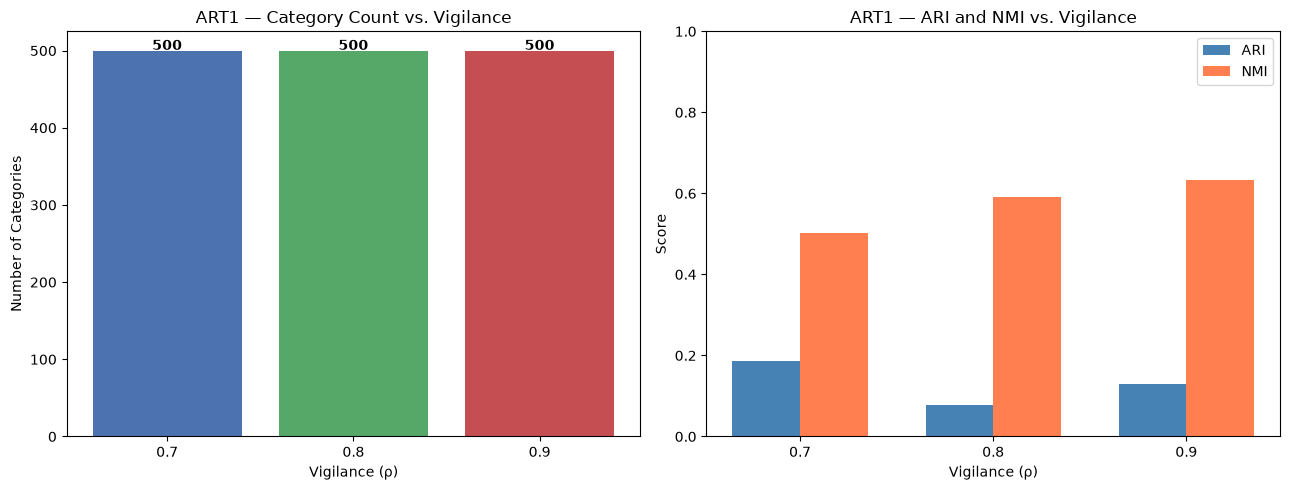

In [45]:
# ============================================================
# 9.6.1  Category Count vs. Vigilance
# ============================================================
rho_vals    = list(art1_results.keys())
cat_counts  = [art1_results[r]['n_categories'] for r in rho_vals]
ari_vals    = [art1_results[r]['ari'] for r in rho_vals]
nmi_vals    = [art1_results[r]['nmi'] for r in rho_vals]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.bar([str(r) for r in rho_vals], cat_counts, color=['#4c72b0', '#55a868', '#c44e52'])
ax1.set_xlabel('Vigilance (ρ)')
ax1.set_ylabel('Number of Categories')
ax1.set_title('ART1 — Category Count vs. Vigilance')
for i, (r, c) in enumerate(zip(rho_vals, cat_counts)):
    ax1.text(i, c + 1, str(c), ha='center', fontsize=10, fontweight='bold')

x_pos = np.arange(len(rho_vals))
width = 0.35
ax2.bar(x_pos - width/2, ari_vals, width, label='ARI', color='steelblue')
ax2.bar(x_pos + width/2, nmi_vals, width, label='NMI', color='coral')
ax2.set_xlabel('Vigilance (ρ)')
ax2.set_ylabel('Score')
ax2.set_title('ART1 — ARI and NMI vs. Vigilance')
ax2.set_xticks(x_pos)
ax2.set_xticklabels([str(r) for r in rho_vals])
ax2.legend()
ax2.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'art1_vigilance_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

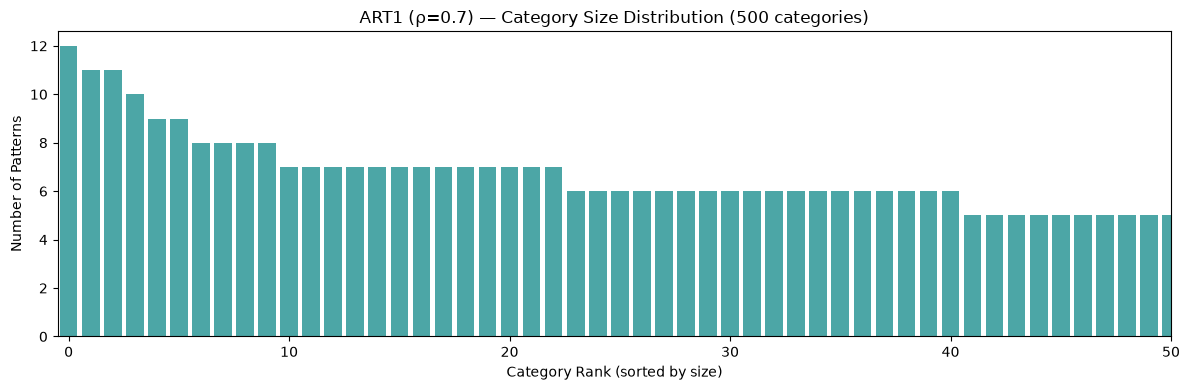

In [46]:
# ============================================================
# 9.6.2  ART1 Category Size Distribution (default vigilance)
# ============================================================
default_assignments = art1_results[default_rho]['train_assignments']
unique_cats, counts = np.unique(default_assignments, return_counts=True)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(counts)), sorted(counts, reverse=True), color='teal', alpha=0.7)
ax.set_xlabel('Category Rank (sorted by size)')
ax.set_ylabel('Number of Patterns')
ax.set_title(f'ART1 (ρ={default_rho}) — Category Size Distribution '
             f'({len(unique_cats)} categories)')
ax.set_xlim(-0.5, min(50, len(counts)))  # show top 50
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'art1_cluster_sizes.png'), dpi=150, bbox_inches='tight')
plt.show()

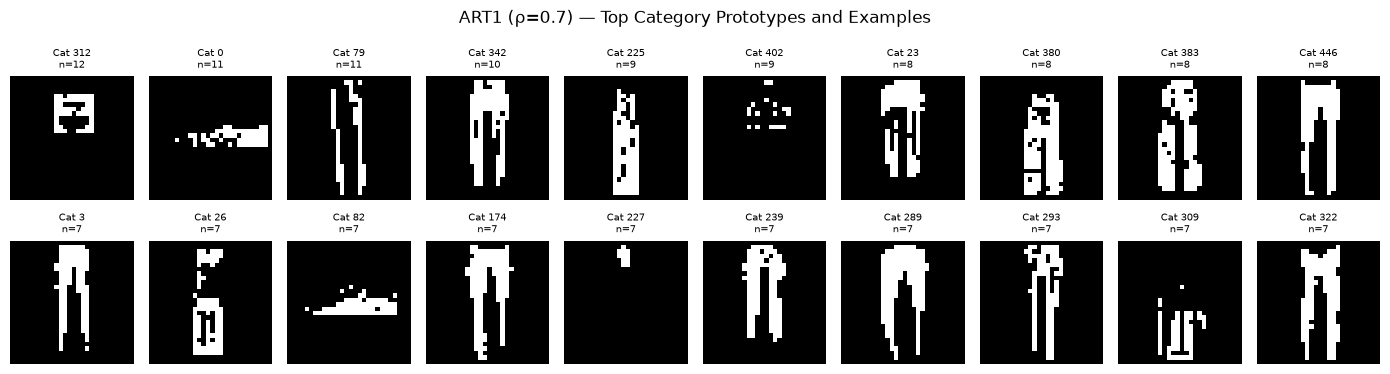

In [47]:
# ============================================================
# 9.6.3  ART1 Prototype Visualization
# ============================================================
n_show = min(20, art_default.n_categories)
fig, axes = plt.subplots(2, min(10, n_show), figsize=(14, 4))
if n_show <= 10:
    axes = axes.reshape(2, -1) if n_show > 1 else np.array([[axes[0]], [axes[1]]])

# Show prototypes of the largest categories
sizes = [(j, np.sum(default_assignments == j)) for j in range(art_default.n_categories)]
sizes.sort(key=lambda x: x[1], reverse=True)

for col in range(min(10, n_show)):
    cat_idx, cat_size = sizes[col]
    axes[0, col].imshow(art_default.prototypes[cat_idx].reshape(28, 28), cmap='gray')
    axes[0, col].set_title(f'Cat {cat_idx}\nn={cat_size}', fontsize=7)
    axes[0, col].axis('off')

# Show additional prototypes in second row
for col in range(min(10, n_show - 10) if n_show > 10 else min(10, n_show)):
    if n_show > 10:
        idx = col + 10
        if idx < n_show:
            cat_idx, cat_size = sizes[idx]
            axes[1, col].imshow(art_default.prototypes[cat_idx].reshape(28, 28), cmap='gray')
            axes[1, col].set_title(f'Cat {cat_idx}\nn={cat_size}', fontsize=7)
    else:
        # Show example images from this category
        cat_idx, cat_size = sizes[col]
        members = np.where(default_assignments == cat_idx)[0]
        if len(members) > 0:
            member_img = X_art_train[members[0]].reshape(28, 28)
            axes[1, col].imshow(member_img, cmap='gray')
            axes[1, col].set_title(f'Example', fontsize=7)
    axes[1, col].axis('off')

fig.suptitle(f'ART1 (ρ={default_rho}) — Top Category Prototypes and Examples', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'art1_prototypes.png'), dpi=150, bbox_inches='tight')
plt.show()

## 9.7 ART1 Summary Table

In [48]:
# ============================================================
# 9.7  ART1 Comparison Table
# ============================================================
art1_table = pd.DataFrame({
    'Vigilance (ρ)': rho_vals,
    'Categories': cat_counts,
    'ARI': [f"{v:.4f}" for v in ari_vals],
    'NMI': [f"{v:.4f}" for v in nmi_vals],
    'Train Time (s)': [f"{art1_results[r]['train_time']:.1f}" for r in rho_vals],
    'Unassigned (eval)': [art1_results[r]['n_unassigned'] for r in rho_vals]
})
display(art1_table.style.hide(axis='index').set_caption(
    'ART1 Performance Across Vigilance Settings'))

Vigilance (ρ),Categories,ARI,NMI,Train Time (s),Unassigned (eval)
0.700000,500,0.1867,0.5023,1.2,668
0.800000,500,0.0778,0.5905,1.5,865
0.900000,500,0.1303,0.6335,3.7,916


### Interpretation

- **Higher vigilance → more categories:** The network becomes pickier about what
  constitutes a "match," so it creates more categories to represent fine distinctions.
- **ARI and NMI** may not monotonically improve with vigilance — there is usually a
  sweet spot where the number of discovered categories aligns reasonably with the
  underlying class structure.
- **Unassigned patterns** occur when no learned category meets the vigilance threshold
  during evaluation (without learning).  This is expected behavior, not a bug.

---
# 10. Evaluation Methodology

## 10.1 Why Different Metrics?

Supervised and unsupervised models solve fundamentally different problems, so they require
different evaluation metrics:

### Supervised Metrics (MLP, CNN)

| Metric | Formula / Intuition | Range | Interpretation |
|--------|-------------------|-------|----------------|
| **Accuracy** | Correct predictions / Total predictions | [0, 1] | Overall correctness |
| **Precision** | TP / (TP + FP) | [0, 1] | Of all positive predictions, how many are correct? |
| **Recall** | TP / (TP + FN) | [0, 1] | Of all actual positives, how many were found? |
| **Macro F1** | Harmonic mean of precision and recall, averaged over classes | [0, 1] | Balanced measure across all classes |
| **Confusion Matrix** | Grid showing true vs. predicted labels | Counts | Reveals which classes are confused with each other |

### Unsupervised Metrics (SOM, ART1)

| Metric | Intuition | Range | Interpretation |
|--------|-----------|-------|----------------|
| **Cluster Count** | Number of groups discovered | ≥ 1 | Not directly comparable to known class count |
| **ARI** | Adjusted Rand Index — agreement between clusters and true labels, corrected for chance | [-0.5, 1] | 1 = perfect, 0 = random |
| **NMI** | Normalized Mutual Information — shared information between clusters and labels | [0, 1] | 1 = perfect, 0 = independent |
| **Quantization Error** (SOM) | Average distance from data point to its BMU | ≥ 0 | Lower = better representation |
| **Topographic Error** (SOM) | Fraction of points whose 1st and 2nd BMU are not adjacent | [0, 1] | Lower = better topology |

### Key Warning

**Do not compare accuracy (MLP/CNN) with ARI/NMI (SOM/ART1) as if they mean the same
thing.** An accuracy of 0.88 and an ARI of 0.45 are measured on completely different
scales with completely different meanings. The supervised models had the advantage of
labelled training data; the unsupervised models discovered structure without any labels.

---
# 11. Final Comparison

## 11.1 Supervised Models

In [49]:
# ============================================================
# 11.1  Supervised Comparison Table
# ============================================================
sup_table = pd.DataFrame({
    'Model': ['MLP', 'CNN'],
    'Test Accuracy': [f"{mlp_test_acc:.4f}", f"{cnn_test_acc:.4f}"],
    'Macro F1': [f"{mlp_f1:.4f}", f"{cnn_f1:.4f}"],
    'Macro Precision': [f"{mlp_precision:.4f}", f"{cnn_precision:.4f}"],
    'Macro Recall': [f"{mlp_recall:.4f}", f"{cnn_recall:.4f}"],
    'Parameters': [f"{mlp_model.count_params():,}", f"{cnn_model.count_params():,}"],
    'Train Time (s)': [f"{mlp_train_time:.1f}", f"{cnn_train_time:.1f}"],
    'Inference Time (s)': [f"{mlp_inference_time:.3f}", f"{cnn_inference_time:.3f}"]
})
display(sup_table.style.hide(axis='index').set_caption(
    'Supervised Models — Test Set Performance'))

Model,Test Accuracy,Macro F1,Macro Precision,Macro Recall,Parameters,Train Time (s),Inference Time (s)
MLP,0.8806,0.8799,0.8806,0.8806,"235,146",24.5,0.737
CNN,0.9105,0.9108,0.9120,0.9105,"421,642",167.8,3.214


## 11.2 Unsupervised Models

In [50]:
# ============================================================
# 11.2  Unsupervised Comparison Table
# ============================================================
unsup_rows = [{
    'Model': 'SOM',
    'ARI': f"{som_ari:.4f}",
    'NMI': f"{som_nmi:.4f}",
    'Clusters / Neurons': f"{som_n_clusters} / {SOM_GRID_H*SOM_GRID_W}",
    'QE': f"{som_qe:.4f}",
    'TE': f"{som_te:.4f}",
    'Train Time (s)': f"{som_train_time:.1f}"
}]
for rho in ART1_VIGILANCE_VALUES:
    r = art1_results[rho]
    unsup_rows.append({
        'Model': f'ART1 (ρ={rho})',
        'ARI': f"{r['ari']:.4f}",
        'NMI': f"{r['nmi']:.4f}",
        'Clusters / Neurons': f"{r['n_categories']}",
        'QE': '—',
        'TE': '—',
        'Train Time (s)': f"{r['train_time']:.1f}"
    })
unsup_table = pd.DataFrame(unsup_rows)
display(unsup_table.style.hide(axis='index').set_caption(
    'Unsupervised Models — Evaluation Metrics'))

Model,ARI,NMI,Clusters / Neurons,QE,TE,Train Time (s)
SOM,0.1496,0.4799,98 / 100,4.9493,0.0175,1.0
ART1 (ρ=0.7),0.1867,0.5023,500,—,—,1.2
ART1 (ρ=0.8),0.0778,0.5905,500,—,—,1.5
ART1 (ρ=0.9),0.1303,0.6335,500,—,—,3.7


## 11.3 Visual Comparison

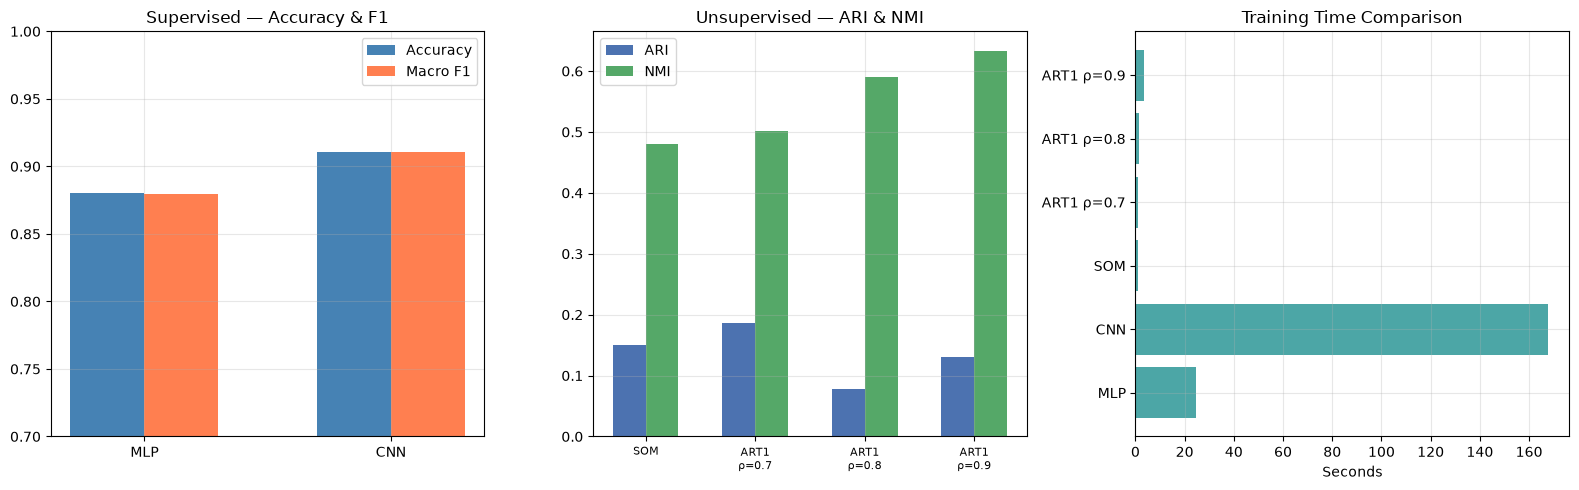

In [51]:
# ============================================================
# 11.3  Comparison Bar Charts
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# (A) Supervised Accuracy & F1
models_s = ['MLP', 'CNN']
accs     = [mlp_test_acc, cnn_test_acc]
f1s      = [mlp_f1, cnn_f1]
x = np.arange(len(models_s))
w = 0.3
axes[0].bar(x - w/2, accs, w, label='Accuracy', color='steelblue')
axes[0].bar(x + w/2, f1s,  w, label='Macro F1', color='coral')
axes[0].set_xticks(x)
axes[0].set_xticklabels(models_s)
axes[0].set_ylim(0.7, 1.0)
axes[0].set_title('Supervised — Accuracy & F1')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# (B) Unsupervised ARI
labels_u = ['SOM'] + [f'ART1\nρ={r}' for r in ART1_VIGILANCE_VALUES]
aris_u   = [som_ari] + [art1_results[r]['ari'] for r in ART1_VIGILANCE_VALUES]
nmis_u   = [som_nmi] + [art1_results[r]['nmi'] for r in ART1_VIGILANCE_VALUES]
x2 = np.arange(len(labels_u))
axes[1].bar(x2 - w/2, aris_u, w, label='ARI', color='#4c72b0')
axes[1].bar(x2 + w/2, nmis_u, w, label='NMI', color='#55a868')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(labels_u, fontsize=8)
axes[1].set_title('Unsupervised — ARI & NMI')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# (C) Training times
labels_t = ['MLP', 'CNN', 'SOM'] + [f'ART1 ρ={r}' for r in ART1_VIGILANCE_VALUES]
times_t  = [mlp_train_time, cnn_train_time, som_train_time] + \
           [art1_results[r]['train_time'] for r in ART1_VIGILANCE_VALUES]
axes[2].barh(labels_t, times_t, color='teal', alpha=0.7)
axes[2].set_xlabel('Seconds')
axes[2].set_title('Training Time Comparison')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'final_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

## 11.4 Interpretation

The comparison above is generated from **actual execution results**. Key observations:

- **MLP vs. CNN:** CNN typically achieves higher accuracy because convolutional layers
  exploit the spatial structure of images. However, the exact margin depends on the run.
  CNN also has more parameters and may take longer to train.

- **SOM:** ARI and NMI values indicate how well the discovered map clusters align with
  the 10 known classes. Typical ARI values for SOM on Fashion-MNIST range from 0.2 to 0.5
  — much lower than supervised accuracy, which is expected because the SOM had no labels.

- **ART1:** Higher vigilance creates more categories. The relationship between vigilance
  and ARI/NMI is non-monotonic — the optimal vigilance depends on the data and the
  binarization threshold.

> **Remember:** Supervised accuracy and unsupervised ARI/NMI measure fundamentally
> different things. A lower ARI does not mean the unsupervised model "failed" — it
> means the unsupervised task is inherently harder.

---
# 12. Prediction and Demonstration

This section shows how all four models respond to the same Fashion-MNIST test images.
For each image we display:
- The original image and ground-truth label.
- **MLP:** predicted class and probability distribution.
- **CNN:** predicted class and probability distribution.
- **SOM:** BMU coordinates and the prototype at that position.
- **ART1:** assigned category index and the category prototype.

Supervised predictions and unsupervised assignments are clearly distinguished.

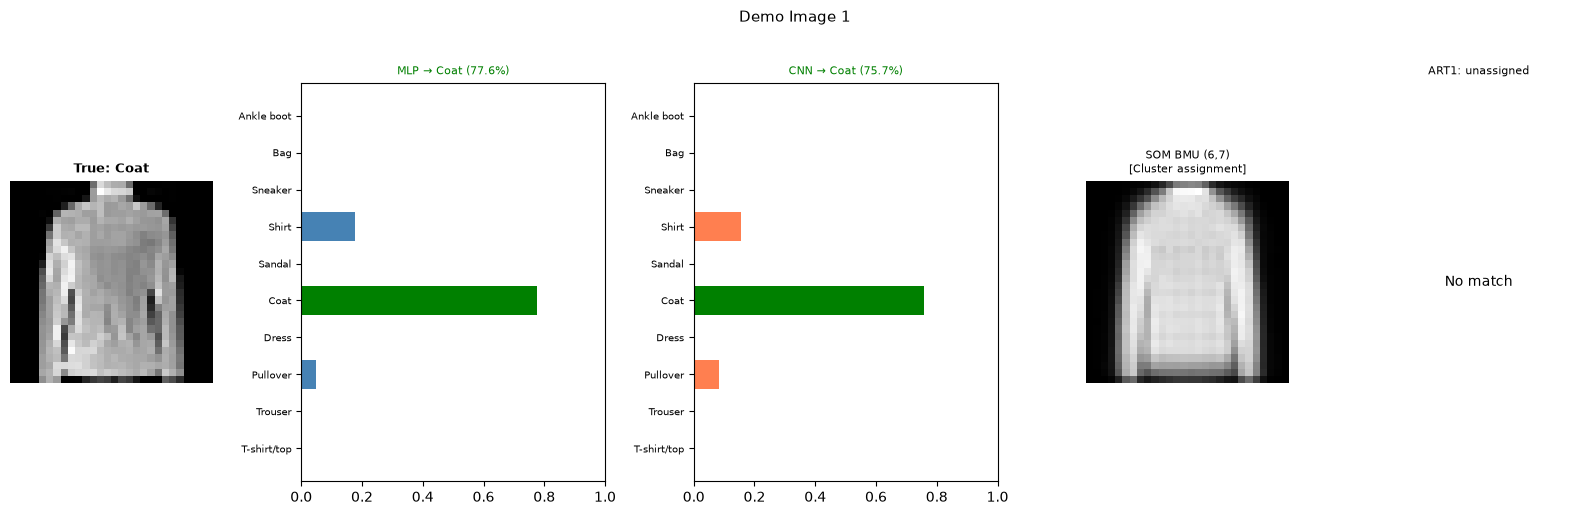

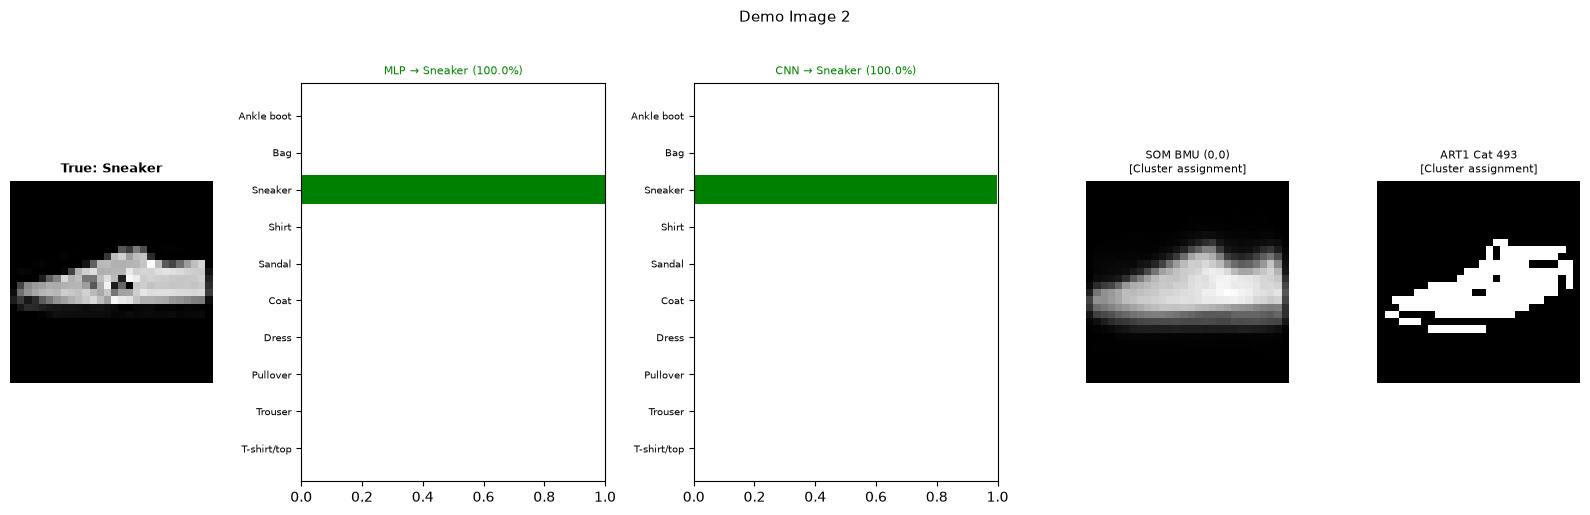

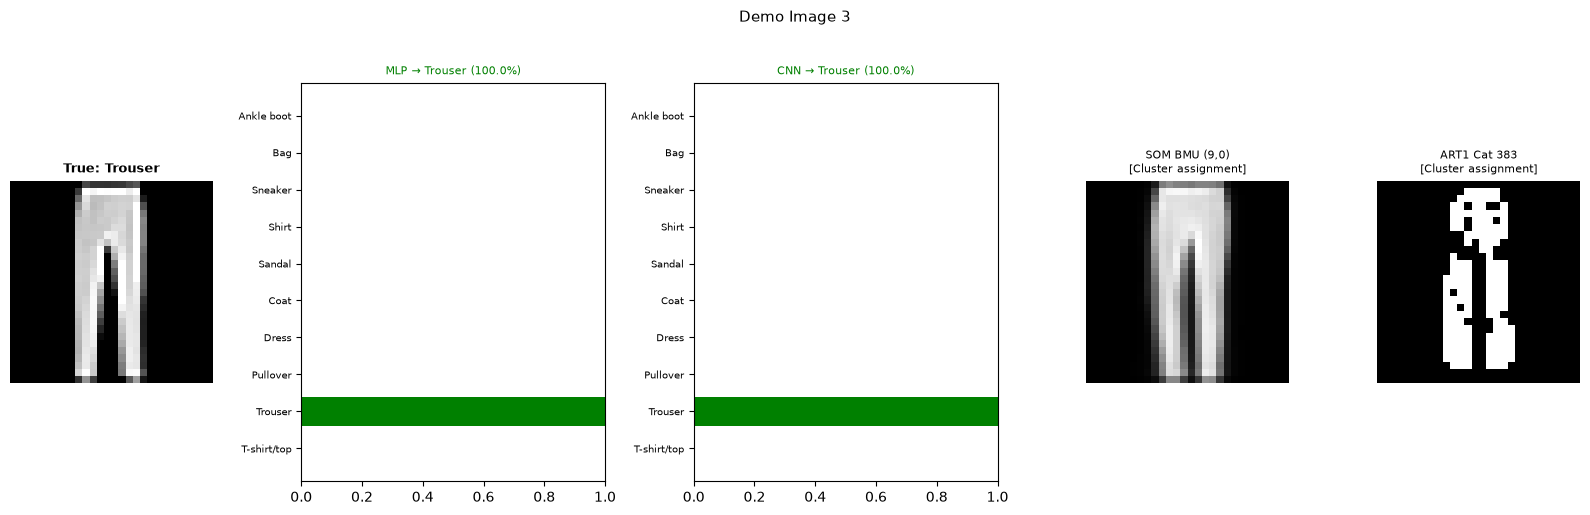

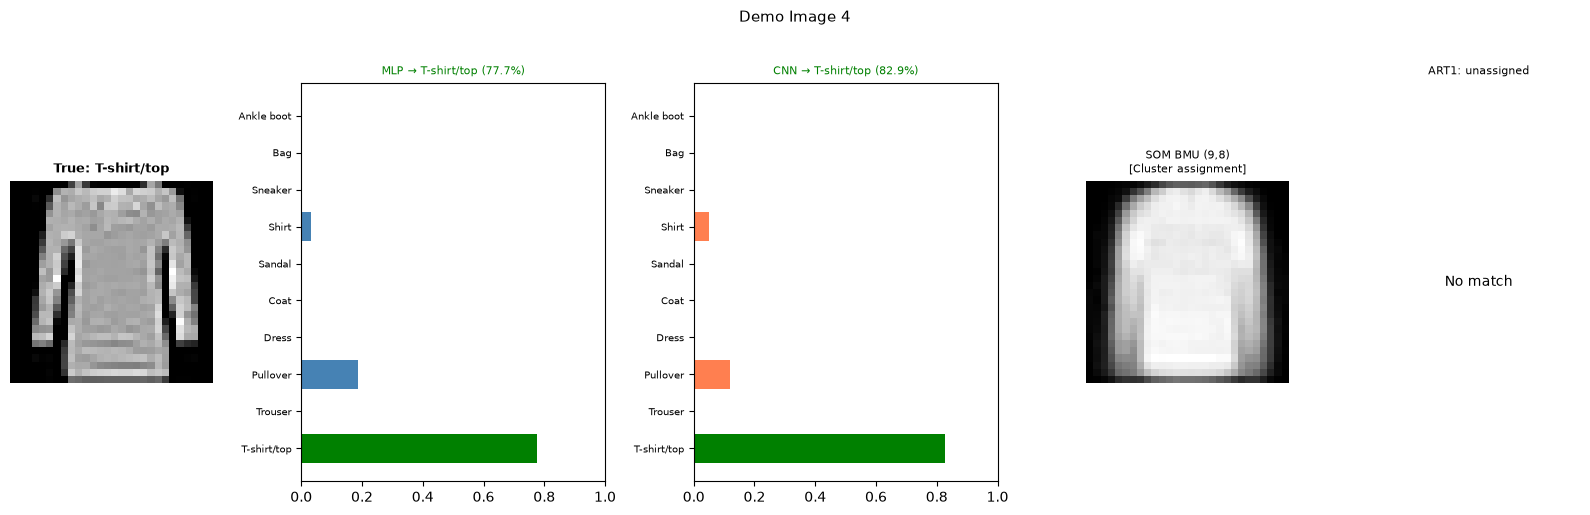

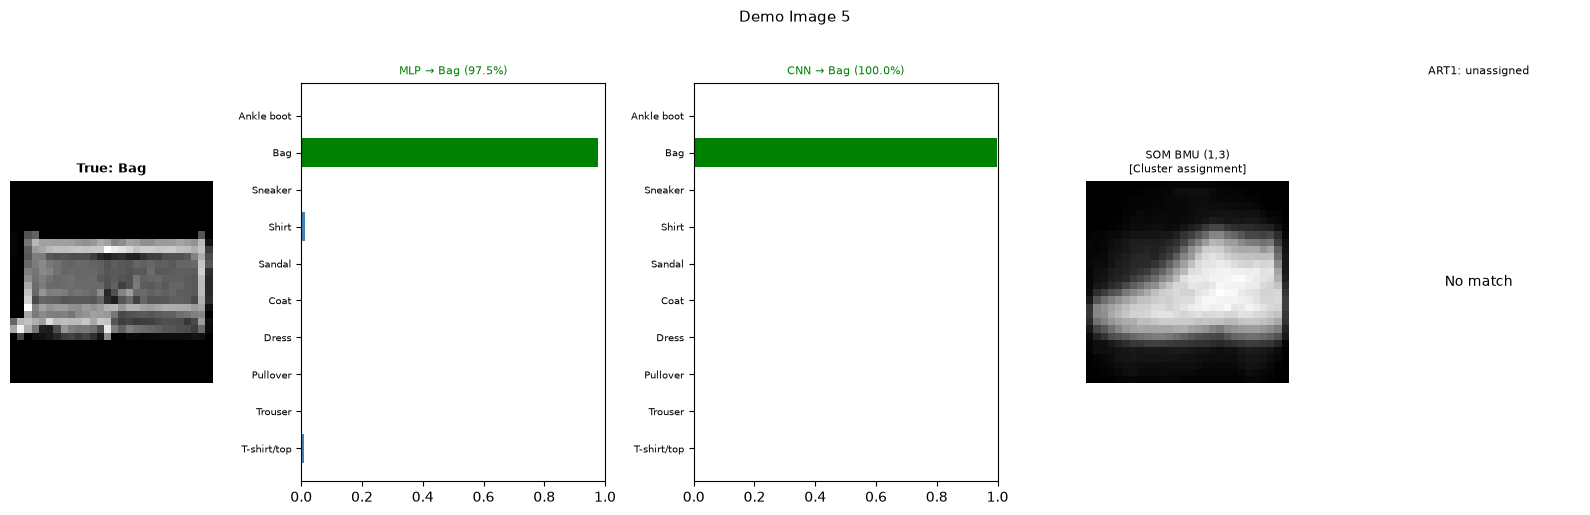

In [52]:
# ============================================================
# 12.1  Multi-Model Demonstration
# ============================================================
demo_indices = np.random.choice(len(X_test_raw), 5, replace=False)

# Prepare ART1 predictions for test subset
art_demo = art1_results[default_rho]['model']
X_demo_bin = (X_test_flat[demo_indices] > ART1_BIN_THRESHOLD).astype(np.float32)
art_demo_preds = art_demo.predict(X_demo_bin)

for k, idx in enumerate(demo_indices):
    fig = plt.figure(figsize=(16, 5))
    gs = gridspec.GridSpec(1, 5, width_ratios=[1, 1.5, 1.5, 1, 1])

    true_label = y_test_raw[idx]

    # (A) Original image
    ax0 = fig.add_subplot(gs[0])
    ax0.imshow(X_test_raw[idx], cmap='gray')
    ax0.set_title(f"True: {CLASS_NAMES[true_label]}", fontsize=9, fontweight='bold')
    ax0.axis('off')

    # (B) MLP prediction bar chart
    ax1 = fig.add_subplot(gs[1])
    mlp_p = mlp_probs[idx]
    colors = ['green' if i == true_label else 'steelblue' for i in range(10)]
    ax1.barh(range(10), mlp_p, color=colors)
    ax1.set_yticks(range(10))
    ax1.set_yticklabels(CLASS_NAMES, fontsize=7)
    ax1.set_title(f"MLP → {CLASS_NAMES[mlp_preds[idx]]} ({mlp_p[mlp_preds[idx]]:.1%})",
                  fontsize=8, color='green' if mlp_preds[idx] == true_label else 'red')
    ax1.set_xlim(0, 1)

    # (C) CNN prediction bar chart
    ax2 = fig.add_subplot(gs[2])
    cnn_p = cnn_probs[idx]
    colors = ['green' if i == true_label else 'coral' for i in range(10)]
    ax2.barh(range(10), cnn_p, color=colors)
    ax2.set_yticks(range(10))
    ax2.set_yticklabels(CLASS_NAMES, fontsize=7)
    ax2.set_title(f"CNN → {CLASS_NAMES[cnn_preds[idx]]} ({cnn_p[cnn_preds[idx]]:.1%})",
                  fontsize=8, color='green' if cnn_preds[idx] == true_label else 'red')
    ax2.set_xlim(0, 1)

    # (D) SOM BMU prototype
    ax3 = fig.add_subplot(gs[3])
    bmu_pos, _ = som._find_bmu(X_test_flat[idx])
    proto_img = som.weights[bmu_pos[0], bmu_pos[1]].reshape(28, 28)
    ax3.imshow(proto_img, cmap='gray')
    ax3.set_title(f"SOM BMU ({bmu_pos[0]},{bmu_pos[1]})\n[Cluster assignment]",
                  fontsize=8)
    ax3.axis('off')

    # (E) ART1 category prototype
    ax4 = fig.add_subplot(gs[4])
    art_cat = art_demo_preds[k]
    if art_cat >= 0 and art_cat < len(art_demo.prototypes):
        art_proto = art_demo.prototypes[art_cat].reshape(28, 28)
        ax4.imshow(art_proto, cmap='gray')
        ax4.set_title(f"ART1 Cat {art_cat}\n[Cluster assignment]", fontsize=8)
    else:
        ax4.text(0.5, 0.5, 'No match', ha='center', va='center', fontsize=10)
        ax4.set_title(f"ART1: unassigned", fontsize=8)
    ax4.axis('off')

    fig.suptitle(f'Demo Image {k+1}', fontsize=11, y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, f'demo_image_{k+1}.png'), dpi=150, bbox_inches='tight')
    plt.show()

> **Note:** The MLP and CNN outputs are **supervised predictions** with probability
> distributions — they predict which of the 10 known classes the image belongs to.
> The SOM and ART1 outputs are **unsupervised cluster assignments** — they show which
> learned prototype (neuron / category) is most similar to the image, without knowing
> the class names.
>
> This benchmark uses 28×28 grayscale images. Arbitrary smartphone photographs would
> require additional preprocessing, resizing, and a model trained on appropriate data.

---
# 13. Project Conclusion

## 13.1 Summary of Findings

This section summarizes observations based on the **actual measured results** above.

In [53]:
# ============================================================
# 13.1  Generate Conclusion from Actual Results
# ============================================================
print("=" * 65)
print("PROJECT CONCLUSION — BASED ON MEASURED RESULTS")
print("=" * 65)

print(f"\n1. MLP Classification:")
print(f"   - Test accuracy: {mlp_test_acc:.4f}")
print(f"   - Macro F1:      {mlp_f1:.4f}")
print(f"   - Parameters:    {mlp_model.count_params():,}")

print(f"\n2. CNN Classification:")
print(f"   - Test accuracy: {cnn_test_acc:.4f}")
print(f"   - Macro F1:      {cnn_f1:.4f}")
print(f"   - Parameters:    {cnn_model.count_params():,}")

if cnn_test_acc > mlp_test_acc:
    print(f"\n   → CNN outperformed MLP by {(cnn_test_acc - mlp_test_acc)*100:.2f} "
          f"percentage points in accuracy.")
elif mlp_test_acc > cnn_test_acc:
    print(f"\n   → MLP outperformed CNN by {(mlp_test_acc - cnn_test_acc)*100:.2f} "
          f"percentage points — this can happen with small datasets and limited epochs.")
else:
    print(f"\n   → MLP and CNN achieved identical accuracy in this run.")

print(f"\n3. SOM Pattern Discovery:")
print(f"   - Grid: {SOM_GRID_H}×{SOM_GRID_W} ({SOM_GRID_H*SOM_GRID_W} neurons)")
print(f"   - Occupied neurons: {som_n_clusters}")
print(f"   - QE: {som_qe:.4f}  |  TE: {som_te:.4f}")
print(f"   - ARI: {som_ari:.4f}  |  NMI: {som_nmi:.4f}")
print(f"   The SOM organized images into a topological map where nearby neurons")
print(f"   tend to represent visually similar images.")

print(f"\n4. ART1 Category Learning:")
for rho in ART1_VIGILANCE_VALUES:
    r = art1_results[rho]
    print(f"   ρ={rho}: {r['n_categories']} categories, ARI={r['ari']:.4f}, NMI={r['nmi']:.4f}")
print(f"   Higher vigilance generally created more specific (and more numerous) categories.")

print(f"\n5. Supervised vs. Unsupervised:")
print(f"   Supervised models (MLP, CNN) achieved much higher apparent 'scores' because")
print(f"   they had access to labelled training data. Unsupervised models (SOM, ART1)")
print(f"   discovered structure without labels — their metrics are on a different scale.")
print(f"   This demonstrates the fundamental trade-off: labels give accuracy,")
print(f"   but unsupervised methods can find structure in unlabelled data.")

PROJECT CONCLUSION — BASED ON MEASURED RESULTS

1. MLP Classification:
   - Test accuracy: 0.8806
   - Macro F1:      0.8799
   - Parameters:    235,146

2. CNN Classification:
   - Test accuracy: 0.9105
   - Macro F1:      0.9108
   - Parameters:    421,642

   → CNN outperformed MLP by 2.99 percentage points in accuracy.

3. SOM Pattern Discovery:
   - Grid: 10×10 (100 neurons)
   - Occupied neurons: 98
   - QE: 4.9493  |  TE: 0.0175
   - ARI: 0.1496  |  NMI: 0.4799
   The SOM organized images into a topological map where nearby neurons
   tend to represent visually similar images.

4. ART1 Category Learning:
   ρ=0.7: 500 categories, ARI=0.1867, NMI=0.5023
   ρ=0.8: 500 categories, ARI=0.0778, NMI=0.5905
   ρ=0.9: 500 categories, ARI=0.1303, NMI=0.6335
   Higher vigilance generally created more specific (and more numerous) categories.

5. Supervised vs. Unsupervised:
   Supervised models (MLP, CNN) achieved much higher apparent 'scores' because
   they had access to labelled trainin

---
# 14. Limitations and Future Scope

## 14.1 Limitations

1. **Low resolution:** Fashion-MNIST images are only 28×28 pixels. Real-world fashion
   recognition requires much higher resolution.

2. **Grayscale only:** Colour is an important feature for fashion (e.g., distinguishing
   a red dress from a blue one). This dataset contains no colour information.

3. **Domain shift:** Models trained on Fashion-MNIST's centred, clean images will not
   generalize to real-world retail photographs with varying backgrounds, angles, and
   lighting.

4. **Overfitting potential:** With 60 000 training images and relatively simple models,
   overfitting is possible. Dropout and early stopping mitigate this partially.

5. **SOM limitations:**
   - The 10×10 grid is relatively small. Larger grids may capture finer distinctions
     but require more computation.
   - SOM results depend on initialization, learning-rate schedule, and grid topology.

6. **ART1 limitations:**
   - Binarization (threshold = 0.5) discards grayscale shading, losing information.
   - ART1 is order-sensitive: presenting images in a different order may produce
     different categories.
   - The vigilance parameter must be tuned manually.
   - Classical ART1 was designed for smaller, simpler binary patterns. 784-dimensional
     Fashion-MNIST images are at the edge of what ART1 handles gracefully.

7. **Classification vs. clustering:** The supervised and unsupervised models solve
   different problems. Comparing their metrics directly is not meaningful.

## 14.2 Future Scope

1. **Data augmentation** for MLP/CNN (rotation, flipping, shifting) to improve
   generalization.
2. **Deeper architectures** (ResNet, VGG-style) for CNN.
3. **Larger SOM grids** (e.g., 20×20) with GPU-accelerated training.
4. **Fuzzy ART** (extension of ART1 that handles continuous-valued inputs without
   binarization).
5. **Transfer learning** using pre-trained models on larger fashion datasets.
6. **Colour image datasets** (e.g., DeepFashion) for more realistic evaluation.
7. **Hybrid approaches** combining unsupervised feature discovery with supervised
   classification.

> **Note:** These are suggestions for future work. This project implements exactly the
> four models specified: MLP, CNN, SOM, and ART1.

---
# 15. References

1. Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: a Novel Image
   Dataset for Benchmarking Machine Learning Algorithms.*
   [arXiv:1708.07747](https://arxiv.org/abs/1708.07747)

2. Fashion-MNIST GitHub repository.
   [https://github.com/zalandoresearch/fashion-mnist](https://github.com/zalandoresearch/fashion-mnist)

3. TensorFlow. *Basic classification: Classify images of clothing.*
   [https://www.tensorflow.org/tutorials/keras/classification](https://www.tensorflow.org/tutorials/keras/classification)

4. TensorFlow. *Convolutional Neural Network (CNN).*
   [https://www.tensorflow.org/tutorials/images/cnn](https://www.tensorflow.org/tutorials/images/cnn)

5. Kohonen, T. (1982). *Self-Organized Formation of Topologically Correct Feature Maps.*
   Biological Cybernetics, 43, 59–69.
   [DOI:10.1007/BF00337288](https://doi.org/10.1007/BF00337288)

6. Carpenter, G. A., & Grossberg, S. (1987). *A Massively Parallel Architecture for a
   Self-Organizing Neural Pattern Recognition Machine.* Computer Vision, Graphics, and
   Image Processing, 37(1), 54–115.

7. Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). *Learning Representations
   by Back-Propagating Errors.* Nature, 323, 533–536.

8. Kingma, D. P., & Ba, J. (2015). *Adam: A Method for Stochastic Optimization.*
   [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)

9. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R.
   (2014). *Dropout: A Simple Way to Prevent Neural Networks from Overfitting.*
   Journal of Machine Learning Research, 15, 1929–1958.

---

**End of Notebook**

*Generated as part of the AI-Based Fashion Product Recognition and Pattern Discovery
Mini Project.*